In [4]:
import pandas as pd

df1 = pd.read_parquet(r"/Users/dror/Projects/EinHamifraz/row1_with_realtime.parquet")
df2 = pd.read_parquet(r"/Users/dror/Projects/EinHamifraz/row2_with_realtime.parquet")
df3 = pd.read_parquet(r"/Users/dror/Projects/EinHamifraz/row3_with_realtime.parquet")




In [5]:
df1.head()

,Ch0,Ch1,Ch2,Ch3,Ch4,Ch5,real time
0,21,86,10,66,202,181,20250902141500
1,21,81,10,65,196,177,20250902141506
2,21,82,10,53,196,176,20250902141512
3,21,84,12,50,196,176,20250902141518
4,21,83,12,50,197,177,20250902141524


In [ ]:
# Shift columns: Ch0→Ch1, Ch1→Ch2, ..., Ch5→Ch6 (add Ch6=NaN)
ch_cols = [f"Ch{i}" for i in range(6) if f"Ch{i}" in df1.columns]
for i in reversed(range(len(ch_cols))):
    src = ch_cols[i]
    dest = f"Ch{i+1}"
    if dest not in df1.columns:
        df1[dest] = pd.NA  # if Ch6 is not present, add as NaN
    df1[dest] = df1[src]
df1.drop(columns=["Ch0"], inplace=True)


In [10]:
df1
df1.to_parquet(r"/Users/dror/Projects/EinHamifraz/row1_with_realtime.parquet")


In [6]:
df2.head()

,Ch1,Ch2,Ch3,Ch4,Ch5,Ch6,time,real time
0,518,535,152,760,485,818,2020-12-31 23:54:50,20250914072000
1,522,534,149,755,484,798,2020-12-31 23:54:56,20250914072006
2,522,536,149,757,483,801,2020-12-31 23:55:02,20250914072012
3,522,535,149,761,478,796,2020-12-31 23:55:08,20250914072018
4,522,527,139,760,477,798,2020-12-31 23:55:14,20250914072024


In [7]:
df3.head()

,Ch1,Ch2,Ch3,Ch4,Ch5,Ch6,time,real time
0,122,398,32,428,0,0,2020-12-31 23:54:50,20250926042000
1,121,393,34,432,0,0,2020-12-31 23:54:56,20250926042006
2,116,388,34,439,0,0,2020-12-31 23:55:02,20250926042012
3,116,387,34,441,0,0,2020-12-31 23:55:08,20250926042018
4,115,380,34,436,0,0,2020-12-31 23:55:14,20250926042024


In [11]:
df1 = pd.read_parquet(r"/Users/dror/Projects/EinHamifraz/row1_with_realtime.parquet")
df1.head()



,Ch1,Ch2,Ch3,Ch4,Ch5,real time,Ch6
0,21,86,10,66,202,20250902141500,181
1,21,81,10,65,196,20250902141506,177
2,21,82,10,53,196,20250902141512,176
3,21,84,12,50,196,20250902141518,176
4,21,83,12,50,197,20250902141524,177


In [18]:
combined.head()


,Ch1,Ch2,Ch3,Ch4,Ch5,real time,Ch6,source,time,real_time_dt,real time +3h
0,21,86,10,66,202,20250902141500,181,row1,NaT,2025-09-02 14:15:00,20250902081500
1,21,81,10,65,196,20250902141506,177,row1,NaT,2025-09-02 14:15:06,20250902081506
2,21,82,10,53,196,20250902141512,176,row1,NaT,2025-09-02 14:15:12,20250902081512
3,21,84,12,50,196,20250902141518,176,row1,NaT,2025-09-02 14:15:18,20250902081518
4,21,83,12,50,197,20250902141524,177,row1,NaT,2025-09-02 14:15:24,20250902081524


/var/folders/gr/6y3_1gdd0y745jwwy_d1j6_80000gn/T/ipykernel_18243/274060091.py:43: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


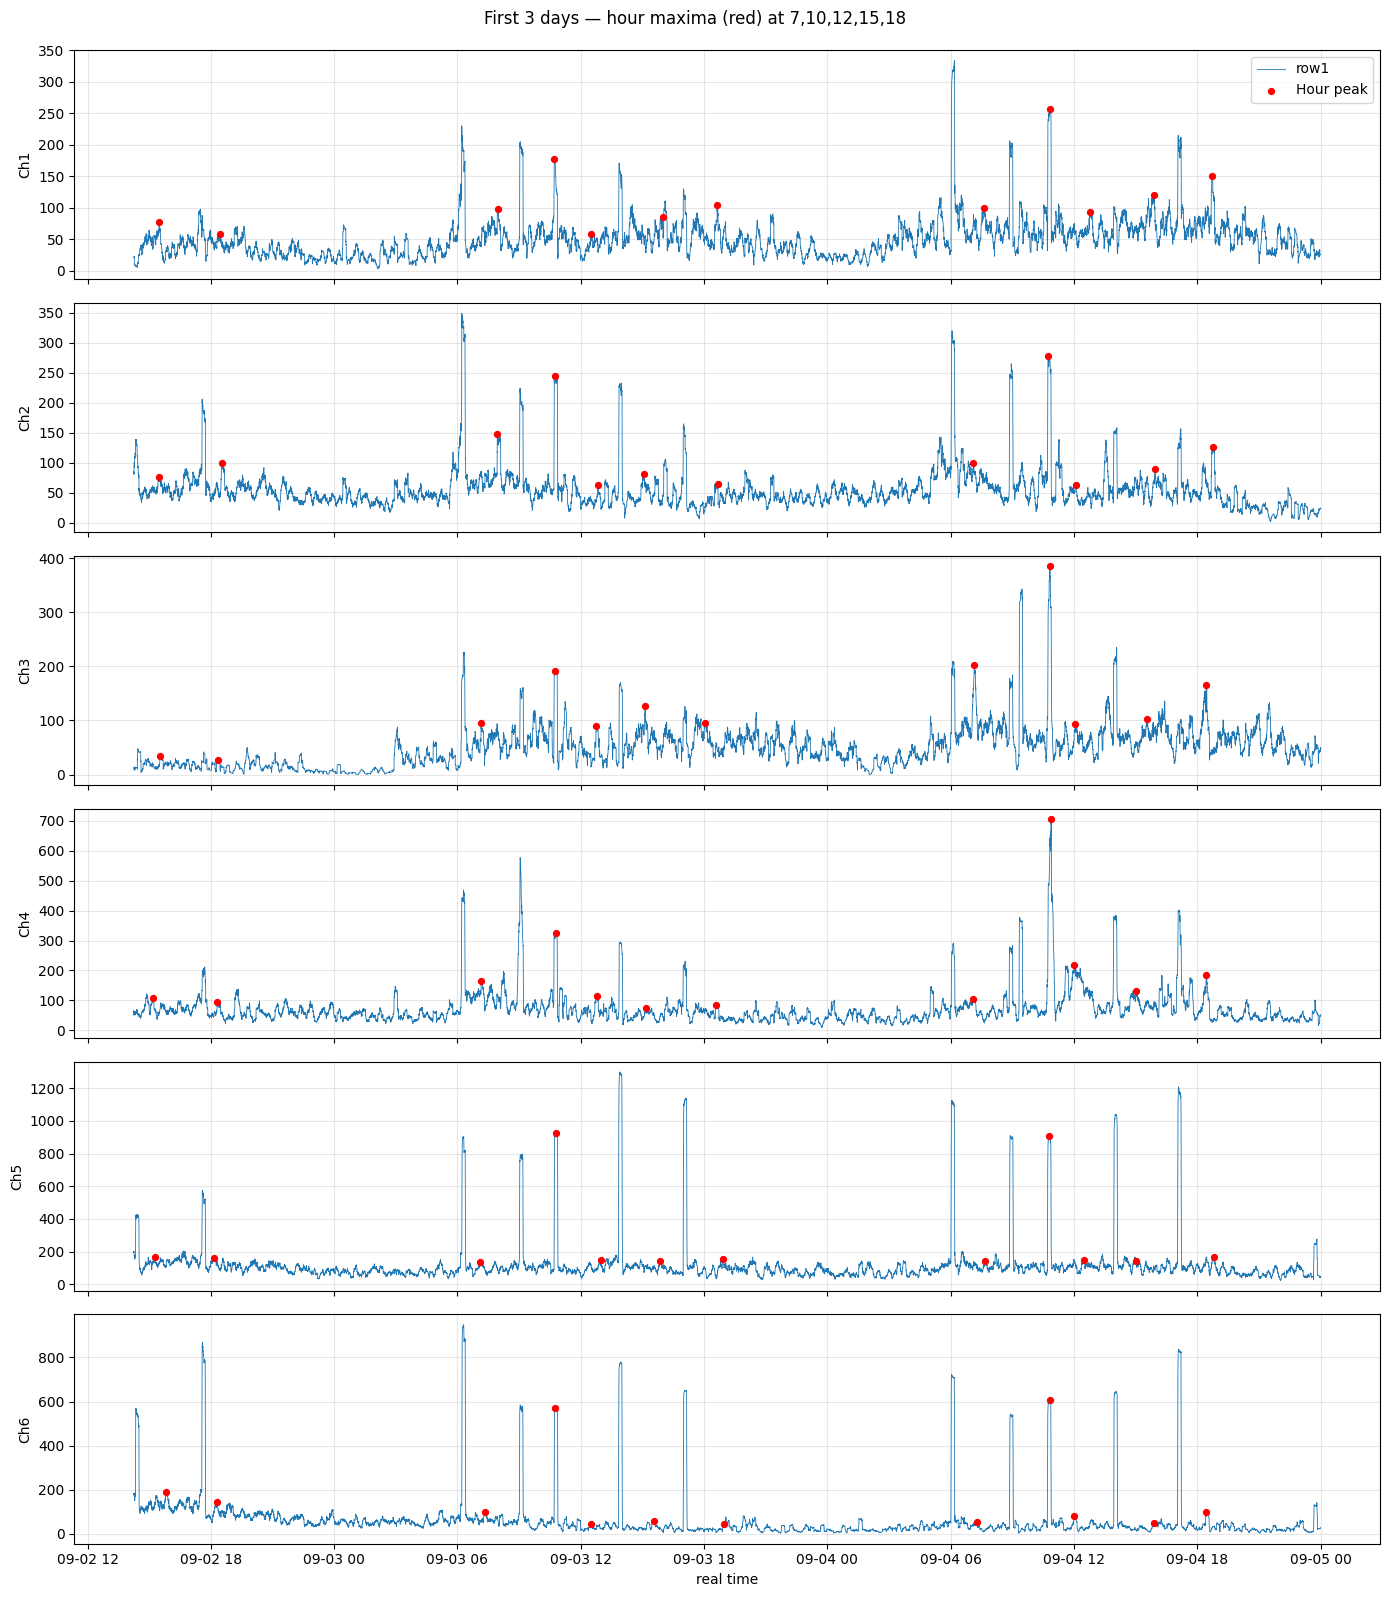

In [23]:
import matplotlib.pyplot as plt
import pandas as pd

# Load combined DataFrame
combined = pd.read_parquet(r"/Users/dror/Projects/EinHamifraz/combiend.parquet")
# Use the original time column for reference
combined["real_time_dt"] = pd.to_datetime(combined["real time"], format="%Y%m%d%H%M%S")
combined = combined.sort_values("real_time_dt")

# Extract first 3 days
first_days = combined["real_time_dt"].dt.normalize().drop_duplicates().iloc[:3]
df_plot = combined[combined["real_time_dt"].dt.normalize().isin(first_days)].copy()

plot_cols = ["Ch1", "Ch2", "Ch3", "Ch4", "Ch5", "Ch6"]
target_hours = [7, 10, 12, 15, 18]

fig, axes = plt.subplots(len(plot_cols), 1, sharex=True, figsize=(14, 16))

for ax, col in zip(axes, plot_cols):
    for source, group in df_plot.groupby("source", sort=False):
        ax.plot(group["real_time_dt"], group[col], label=source, linewidth=0.6)
    # Highlight peaks at specified hours for each day
    peak_times = []
    peak_vals = []
    for day, day_group in df_plot.groupby(df_plot["real_time_dt"].dt.normalize()):
        for hr in target_hours:
            mask = day_group["real_time_dt"].dt.hour == hr
            window = day_group.loc[mask, :]
            if not window.empty:
                idxmax = window[col].idxmax()
                peak_times.append(window.loc[idxmax, "real_time_dt"])
                peak_vals.append(window.loc[idxmax, col])
    if peak_times:
        ax.scatter(peak_times, peak_vals, c="red", s=18, zorder=5, label="Hour peak")
    ax.set_ylabel(col)
    ax.grid(True, alpha=0.3)

axes[0].legend(loc="upper right")
axes[-1].set_xlabel("real time")

fig.suptitle("First 3 days — hour maxima (red) at 7,10,12,15,18", y=0.995)
fig.tight_layout()
fig.show()

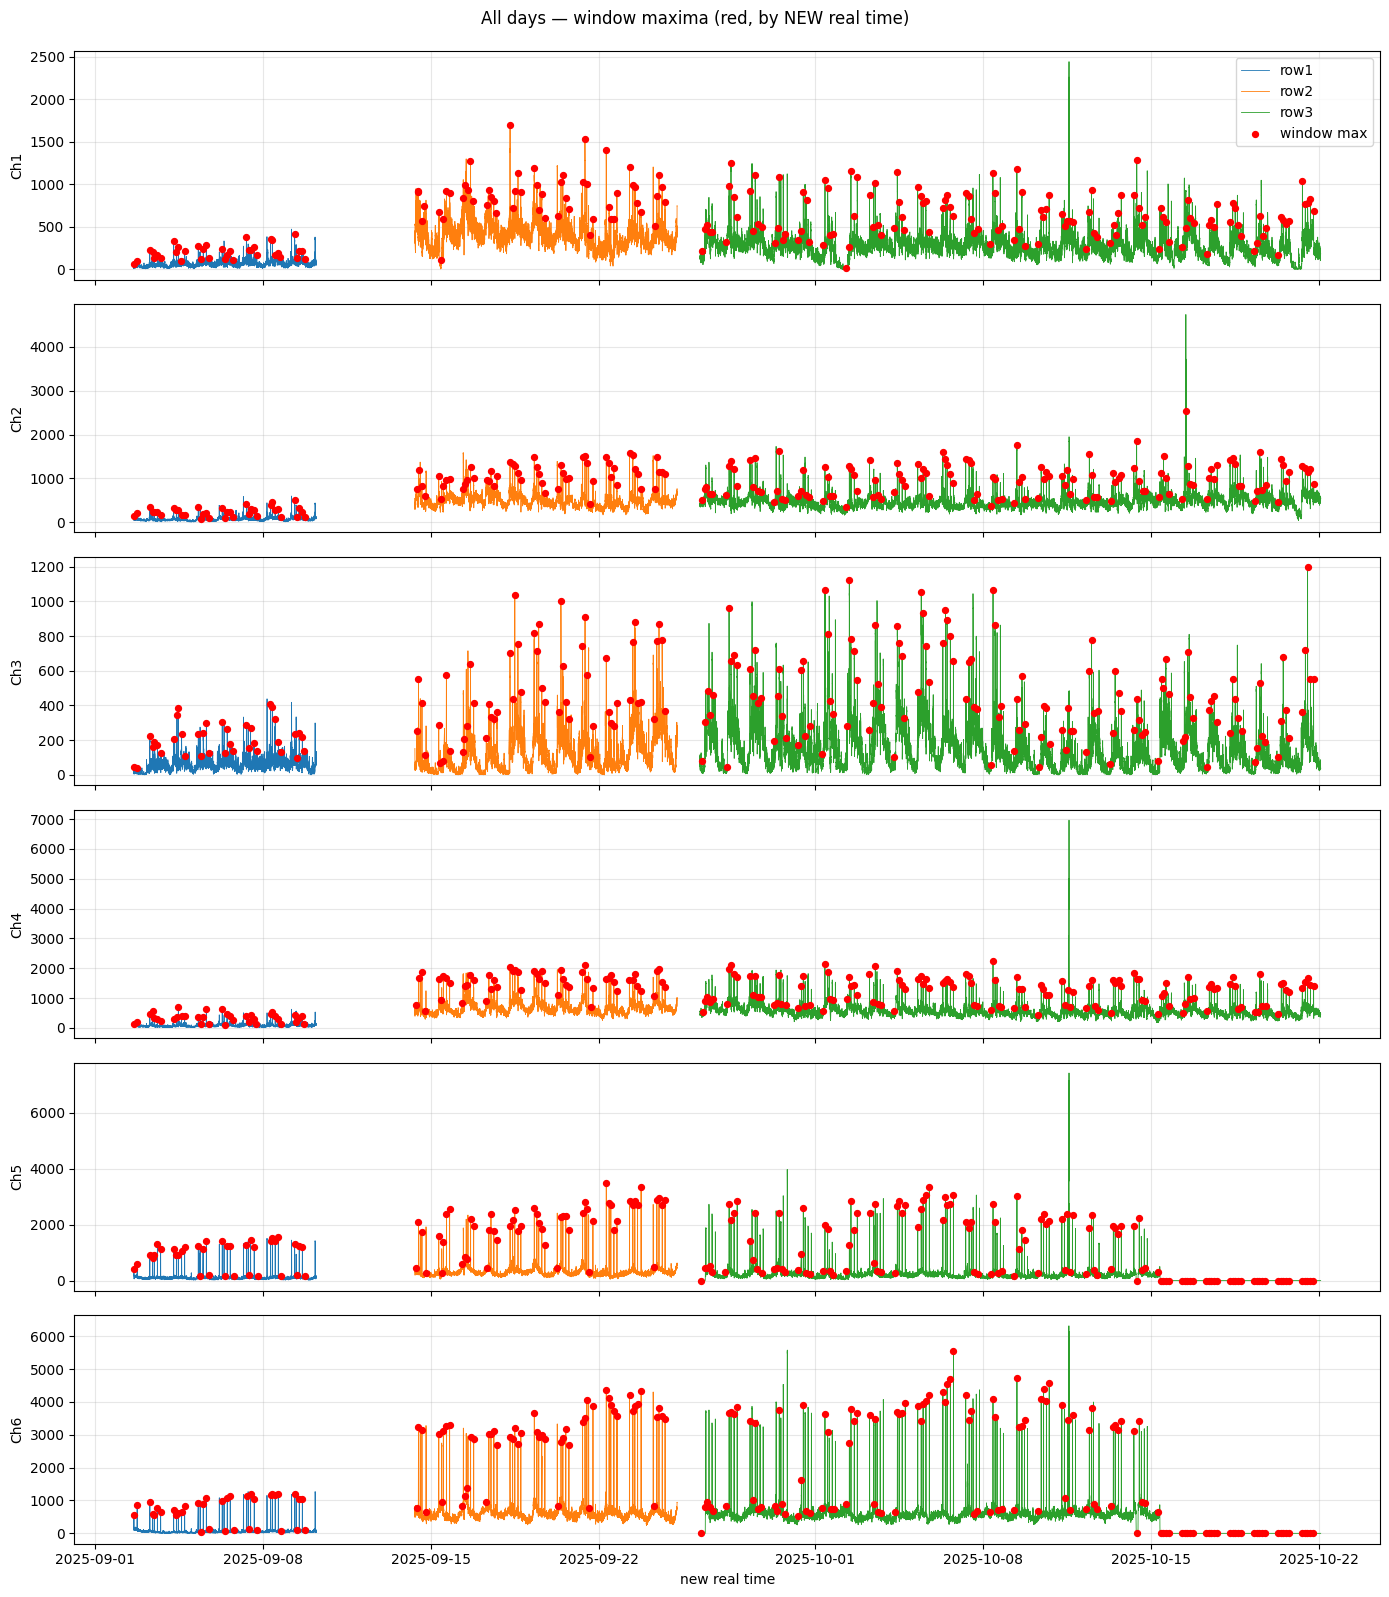

In [36]:
from datetime import datetime
import matplotlib.pyplot as plt
import pandas as pd

combined = pd.read_parquet(r"/Users/dror/Projects/EinHamifraz/combiend.parquet")
combined["new real time"] = (pd.to_datetime(combined["real time"], format="%Y%m%d%H%M%S") + pd.Timedelta(hours=0.7)).dt.strftime("%Y%m%d%H%M%S")

# Use the new real time as datetime for plotting
df = combined.copy()
df["new_real_time_dt"] = pd.to_datetime(df["new real time"], format="%Y%m%d%H%M%S")
df = df.sort_values("new_real_time_dt")
# No day filtering - plot all days

WINDOWS = [
    ("06:30", "07:50"),
    ("09:30", "10:40"),
    ("11:30", "12:50"),
    ("14:30", "15:50"),
    ("17:30", "18:50"),
]

plot_cols = ["Ch1", "Ch2", "Ch3", "Ch4", "Ch5", "Ch6"]
tod = df["new_real_time_dt"].dt.hour * 60 + df["new_real_time_dt"].dt.minute
day = df["new_real_time_dt"].dt.normalize()

fig, axes = plt.subplots(len(plot_cols), 1, sharex=True, figsize=(14, 16))

for ax, col in zip(axes, plot_cols):
    for source, group in df.groupby("source", sort=False):
        ax.plot(group["new_real_time_dt"], group[col], label=source, linewidth=0.6)

    peak_times = []
    peak_vals = []
    for start_s, end_s in WINDOWS:
        start = datetime.strptime(start_s, "%H:%M")
        end = datetime.strptime(end_s, "%H:%M")
        start_m = start.hour * 60 + start.minute
        end_m = end.hour * 60 + end.minute
        mask = (tod >= start_m) & (tod <= end_m)
        window = df.loc[mask, [col]].assign(_day=day[mask], _t=df.loc[mask, "new_real_time_dt"])
        if window.empty:
            continue
        idx = window.groupby("_day")[col].idxmax()
        peaks = window.loc[idx]
        peak_times.append(peaks["_t"])
        peak_vals.append(peaks[col])

    if peak_times:
        ax.scatter(
            pd.concat(peak_times),
            pd.concat(peak_vals),
            c="red",
            s=18,
            zorder=5,
            label="window max",
        )

    ax.set_ylabel(col)
    ax.grid(True, alpha=0.3)

axes[0].legend(loc="upper right")
axes[-1].set_xlabel("new real time")
fig.suptitle("All days — window maxima (red, by NEW real time)", y=0.995)
fig.tight_layout()
fig.savefig("stress_window_maxima.png", dpi=150)
plt.show()


,new_real_time_dt,Ch4


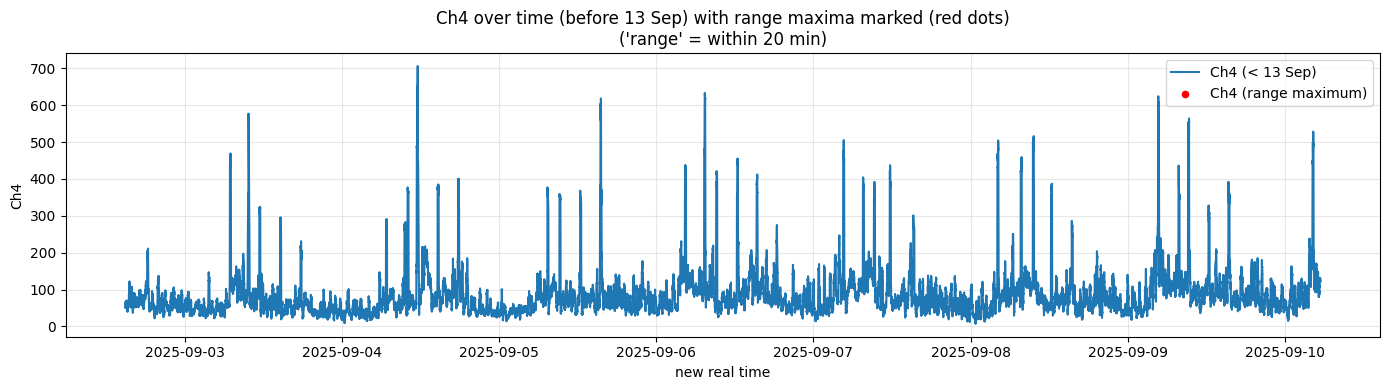

In [95]:
# Only analyze Ch4 before 13th of September (exclusive)
# Here, we define the same "range" as any points within 20 minutes of each other (rolling window grouping by time).

from IPython.display import display

# 1. Filter data to before 13 September
cutoff_date = pd.to_datetime("2025-09-13")
mask_date = df["new_real_time_dt"] < cutoff_date

# 2. Select only Ch4 column and timestamps before cutoff
Ch4_data = df.loc[mask_date, ["new_real_time_dt", "Ch4"]].copy()

# 3. Set a threshold for Ch4 (likely indicating "event" or "range")
threshold = 1000

Ch4_above_threshold = Ch4_data[Ch4_data["Ch4"] > threshold].copy()

# 4. Sort by time just in case
Ch4_above_threshold = Ch4_above_threshold.sort_values("new_real_time_dt")

# 5. Define "same range" as consecutive points within 20 minutes of each other
time_diffs = Ch4_above_threshold["new_real_time_dt"].diff()
# Mark range break where time diff > 20 min or if first row (NA)
group_breaks = (time_diffs > pd.Timedelta(minutes=20)) | (time_diffs.isnull())
group_num = group_breaks.cumsum()
Ch4_above_threshold["group"] = group_num.values

# 6. For each group/range, take the row with the highest Ch4 value
group_maxes = Ch4_above_threshold.loc[
    Ch4_above_threshold.groupby("group")["Ch4"].idxmax()
]

# Display result for verification
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(group_maxes[["new_real_time_dt", "Ch4"]])

# Plot for visual check
plt.figure(figsize=(14, 4))
plt.plot(
    df.loc[mask_date, "new_real_time_dt"],
    df.loc[mask_date, "Ch4"],
    label="Ch4 (< 13 Sep)"
)
plt.scatter(
    group_maxes["new_real_time_dt"],
    group_maxes["Ch4"],
    c="red",
    s=20,
    zorder=5,
    label="Ch4 (range maximum)"
)
plt.xlabel("new real time")
plt.ylabel("Ch4")
plt.title("Ch4 over time (before 13 Sep) with range maxima marked (red dots)\n('range' = within 20 min)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#group_maxes.to_csv("start_feeding_times_ch4_before_13sep.csv", index=False)

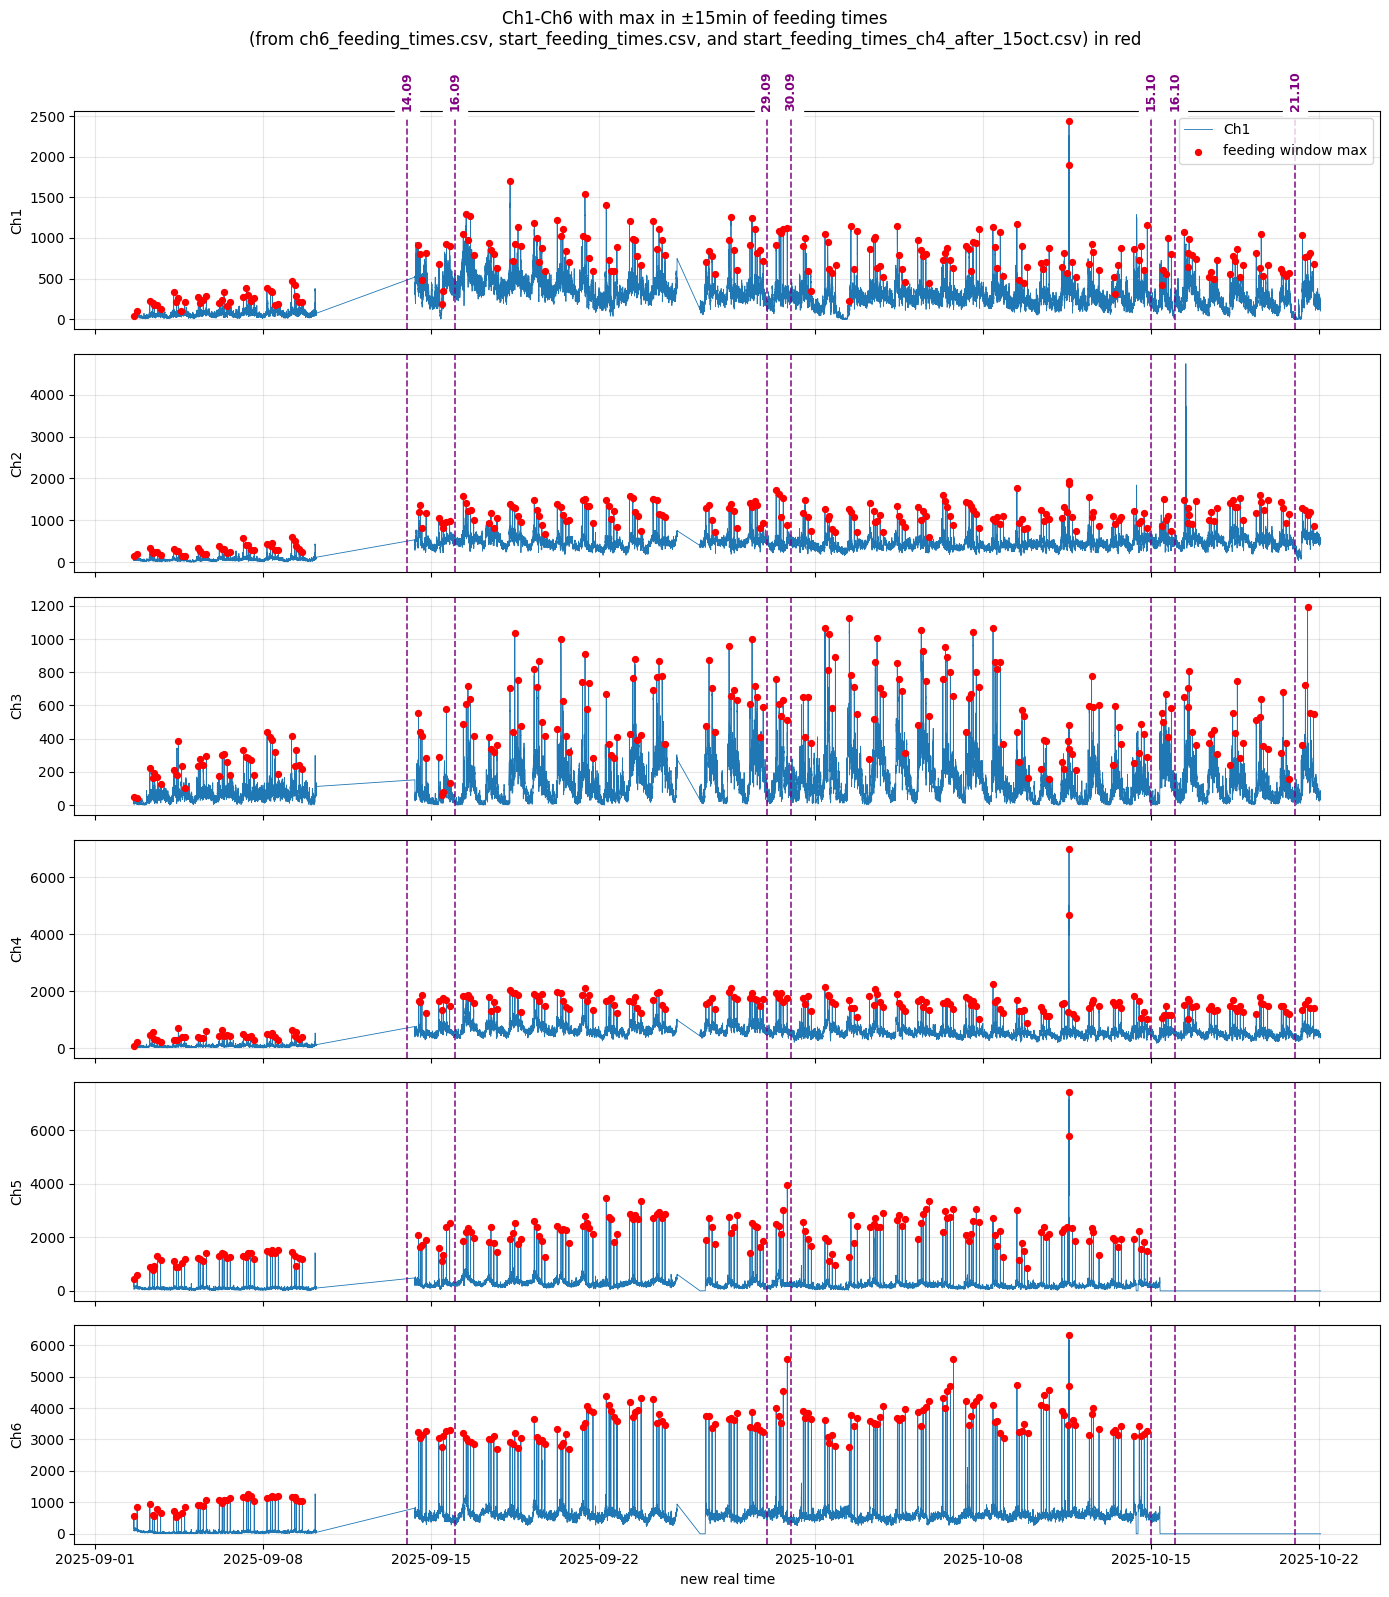

In [80]:
import pandas as pd
import matplotlib.pyplot as plt
from datetime import timedelta, datetime

# Load all three feeding times files
ch6_feed = pd.read_csv("ch6_feeding_times.csv", parse_dates=["new_real_time_dt"])
start_feed = pd.read_csv("start_feeding_times.csv", parse_dates=["new_real_time_dt"])
ch4_after_15oct = pd.read_csv("start_feeding_times_ch4_after_15oct.csv", parse_dates=["new_real_time_dt"])

# We assume 'df' is already loaded (from previous cells) with "new_real_time_dt" and Ch1-Ch6 columns
plot_cols = ["Ch1", "Ch2", "Ch3", "Ch4", "Ch5", "Ch6"]

fig, axes = plt.subplots(len(plot_cols), 1, sharex=True, figsize=(14, 16))

# Prepare for faster subsetting by setting index (if not already)
if not df.index.is_monotonic_increasing or df.index.name != "new_real_time_dt":
    df_timeindexed = df.set_index("new_real_time_dt")
else:
    df_timeindexed = df

window_minutes = 15

# Dates for vertical lines (using 2025 as a stand-in year; adjust if your data uses another year)
vline_dates = [
    datetime(2025, 9, 14),
    datetime(2025, 9, 16),
    datetime(2025, 9, 29),
    datetime(2025, 9, 30),
    datetime(2025, 10, 15),
    datetime(2025, 10, 16),
    datetime(2025, 10, 21)
]
# Optionally, add Hebrew annotation for 15 אוקטובר etc.
vline_labels = [
    "14.09",
    "16.09",
    "29.09",
    "30.09",
    "15.10",
    "16.10",
    "21.10"
]

# Combine all feeding times, including the one from ch4_after_15oct, dropping duplicates (if any overlap)
all_feed_times = pd.concat([
    ch6_feed["new_real_time_dt"],
    start_feed["new_real_time_dt"],
    ch4_after_15oct["new_real_time_dt"],
]).drop_duplicates().sort_values().reset_index(drop=True)

# DataFrame to store feeding-related maxima for all channels
feeding_values_records = []

# Date cutoff: last date where Ch5 and Ch6 exist
ch5_ch6_cutoff = datetime(2025, 10, 15)

for i, col in enumerate(plot_cols):
    ax = axes[i]
    ax.plot(df["new_real_time_dt"], df[col], label=col, linewidth=0.6)

    peak_times = []
    peak_vals = []
    # For each feeding time (from any file), take data +/- 15min and pick the highest value for this channel
    for feed_time in all_feed_times:
        # For Ch5 and Ch6, only process feeding times on or before ch5_ch6_cutoff
        if col in ["Ch5", "Ch6"] and feed_time > ch5_ch6_cutoff:
            continue
        start_time = feed_time - timedelta(minutes=window_minutes)
        end_time = feed_time + timedelta(minutes=window_minutes)
        subset = df_timeindexed.loc[start_time:end_time]
        if not subset.empty:
            idxmax = subset[col].idxmax()
            peak_times.append(idxmax)
            peak_vals.append(subset.loc[idxmax, col])

            # For the first channel, collect all column values at this peak index for the feeding_values df
            # Only collect ONCE for each unique idxmax
            if col == plot_cols[0]:
                full_row = subset.loc[idxmax, plot_cols].to_dict()
                record = {"max_time": idxmax}
                record.update({k: v for k, v in full_row.items()})
                feeding_values_records.append(record)

    if peak_times:
        ax.scatter(
            peak_times,
            peak_vals,
            c="red",
            s=18,
            zorder=5,
            label="feeding window max" if i == 0 else None  # only label once for legend
        )

    # Draw vertical lines
    for vld, vll in zip(vline_dates, vline_labels):
        ax.axvline(vld, color="purple", linestyle="--", linewidth=1.2, alpha=0.9)
        # Only label on the first axis to prevent clutter
        if i == 0:
            ax.text(vld, ax.get_ylim()[1], vll, color="purple", rotation=90,
                    va='bottom', ha='center', fontsize=9, fontweight='bold',
                    backgroundcolor="white")
    ax.set_ylabel(col)
    ax.grid(True, alpha=0.3)

axes[0].legend(loc="upper right")
axes[-1].set_xlabel("new real time")
fig.suptitle(
    "Ch1-Ch6 with max in ±15min of feeding times\n(from ch6_feeding_times.csv, start_feeding_times.csv, and start_feeding_times_ch4_after_15oct.csv) in red",
    y=0.995,
)
fig.tight_layout()
fig.savefig("ch1-6_feeding_times.png", dpi=150)
plt.show()

# Save feeding values DataFrame containing all channel values at max time near feeding events
feeding_values = pd.DataFrame(feeding_values_records)
# Remove duplicate rows by max_time, in case same timestamp appears in multiple feeding windows (for Ch1 maximas)
feeding_values = feeding_values.drop_duplicates(subset=["max_time"])
# Save out, including all columns and max_time ("max_time" is the datetime of the red dot for each feeding window)
feeding_values.to_csv("feeding_values.csv", index=False)

Info: Created 'new_real_time_dt' from column 'real time'.
Selected span: 518394.00 sec = 6.00 days
Ranges where Ch6 > 400 (close ranges merged) for days 13-16:
  Index 0-86399, 86400 samples, Time 2025-09-15 14:15:00 to 2025-09-21 14:14:54


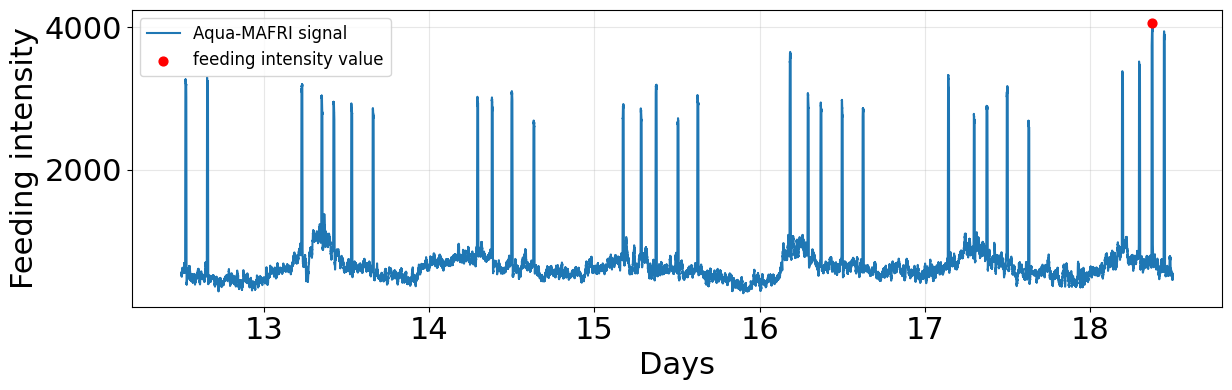

In [250]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Constants for this data
seconds_per_sample = 6

# Load the full dataframe
df = pd.read_parquet("/Users/dror/Projects/EinHamifraz/combiend.parquet")

# Reset index so that the first row is index 0 for counting
df = df.reset_index(drop=True)

# Attempt to make sure 'new_real_time_dt' exists or can be constructed
if "new_real_time_dt" not in df.columns:
    # Try to construct 'new_real_time_dt' from a possible alternative column
    alt_cols = [
        col for col in df.columns 
        if "real" in col and ("time" in col or "dt" in col)
    ]
    dt_col_used = None
    for candidate in alt_cols:
        if pd.api.types.is_datetime64_any_dtype(df[candidate]):
            df["new_real_time_dt"] = df[candidate]
            dt_col_used = candidate
            break
        # If column is integer/str and looks like YYYYMMDDHHmmss
        if (df[candidate].dtype == "int64" or df[candidate].dtype == "object") and df[candidate].astype(str).str.match(r"\d{14}").all():
            # Convert to datetime
            df["new_real_time_dt"] = pd.to_datetime(df[candidate].astype(str), format="%Y%m%d%H%M%S", errors="coerce")
            dt_col_used = candidate
            break
    if dt_col_used:
        print(f"Info: Created 'new_real_time_dt' from column '{dt_col_used}'.")
        if df["new_real_time_dt"].isna().any():
            raise ValueError(f"Failed to parse datetimes in column '{dt_col_used}' to create 'new_real_time_dt'.")
    else:
        print(f"Available columns: {list(df.columns)}")
        raise ValueError("Missing 'new_real_time_dt' column in DataFrame and could not infer from similar columns!")
else:
    df["new_real_time_dt"] = pd.to_datetime(df["new_real_time_dt"])

# Compute days since start
start_time = df["new_real_time_dt"].iloc[0]
df["days"] = (df["new_real_time_dt"] - start_time).dt.total_seconds() / 86400

# Select days 13-16 (inclusive of day 13, exclusive of day 17)
start_day = 13
end_day = 19
mask = (df["days"] >= start_day) & (df["days"] < end_day)

df_selected = df.loc[mask].reset_index(drop=True)
x_selected = df_selected["days"]

# For debugging: print the time span
if not df_selected.empty:
    t0 = df_selected["new_real_time_dt"].iloc[0]
    t1 = df_selected["new_real_time_dt"].iloc[-1]
    total_seconds = (t1 - t0).total_seconds()
    total_days = total_seconds / 86400
    print(f"Selected span: {total_seconds:.2f} sec = {total_days:.2f} days")
else:
    print("Selected range for days 13-16 is empty!")

# Plot Ch6 vs days (since dataset start), restrict to days 13-16, and annotate maxima:
if "Ch6" in df_selected.columns and not df_selected.empty:
    # 'x_selected' is already 'days since start'
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(x_selected, df_selected["Ch6"], label="Aqua-MAFRI signal")
    ax.set_xlabel("Days", fontsize=22)
    ax.set_ylabel("Feeding intensity", fontsize=22)

    # --- Custom 12:00 ticks (for days 13-16) ---
    shown_days = np.arange(start_day, end_day)
    xticks = shown_days + 0.5  # ticks at 12:00
    ax.set_xticks(xticks)
    ax.set_xticklabels([f"{int(val+0.5)}" for val in shown_days], fontsize=22)

    # Find ranges where Ch6 is above 400 (only in selected data)
    above_400 = df_selected["Ch6"] > 400
    groups = []
    in_range = False
    start_idx = None
    for i, is_above in enumerate(above_400):
        if is_above and not in_range:
            in_range = True
            start_idx = i
        elif not is_above and in_range:
            in_range = False
            end_idx = i - 1
            groups.append((start_idx, end_idx))
    if in_range:
        groups.append((start_idx, len(df_selected) - 1))

    # Merge close groups if within 500 samples
    if groups:
        merged_groups = []
        prev_start, prev_end = groups[0]
        for curr_start, curr_end in groups[1:]:
            if curr_start - prev_end <= 500:
                prev_end = curr_end
            else:
                merged_groups.append((prev_start, prev_end))
                prev_start, prev_end = curr_start, curr_end
        merged_groups.append((prev_start, prev_end))
    else:
        merged_groups = groups

    # Print the ranges
    print("Ranges where Ch6 > 400 (close ranges merged) for days 13-16:")
    for start, end in merged_groups:
        start_time = df_selected["new_real_time_dt"].iloc[start]
        end_time = df_selected["new_real_time_dt"].iloc[end]
        print(f"  Index {start}-{end}, {end - start + 1} samples, Time {start_time} to {end_time}")

    # For each group, pick the index of the highest Ch6 value in the range
    red_dots_x = []
    red_dots_y = []
    for start, end in merged_groups:
        group_slice = df_selected.iloc[start:end+1]
        max_idx_in_group = group_slice["Ch6"].idxmax()
        # Since group_slice's index is global, but x_selected and df_selected are aligned:
        rel_idx = df_selected.index.get_loc(max_idx_in_group)
        red_dots_x.append(x_selected.iloc[rel_idx])
        red_dots_y.append(df_selected["Ch6"].iloc[rel_idx])

    ax.scatter(red_dots_x, red_dots_y, color="red", s=40, zorder=5, label="feeding intensity value")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    ax.tick_params(axis='both', which='major', labelsize=22)
    legend = ax.legend(fontsize=12, loc="upper left")
    plt.show()
else:
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


KeyError: "None of ['new_real_time_dt'] are in the columns"

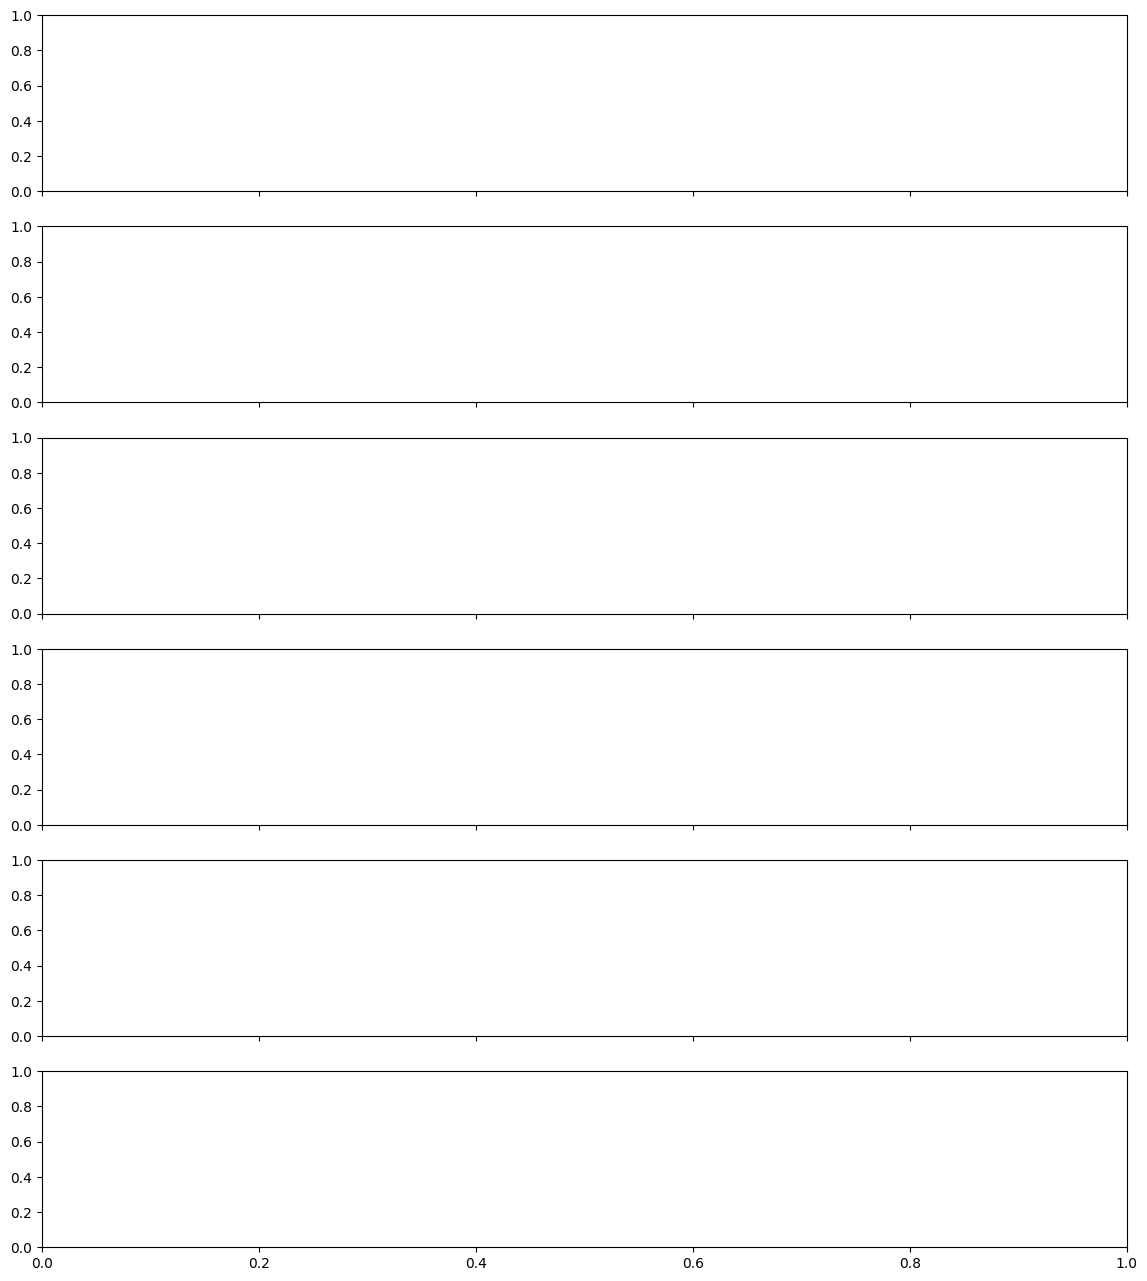

In [228]:
import pandas as pd
import matplotlib.pyplot as plt
from datetime import timedelta, datetime

# Load all three feeding times files
ch6_feed = pd.read_csv("ch6_feeding_times.csv", parse_dates=["new_real_time_dt"])
start_feed = pd.read_csv("start_feeding_times.csv", parse_dates=["new_real_time_dt"])
ch4_after_15oct = pd.read_csv("start_feeding_times_ch4_after_15oct.csv", parse_dates=["new_real_time_dt"])

# We assume 'df' is already loaded (from previous cells) with "new_real_time_dt" and Ch1-Ch6 columns
plot_cols = ["Ch1", "Ch2", "Ch3", "Ch4", "Ch5", "Ch6"]

fig, axes = plt.subplots(len(plot_cols), 1, sharex=True, figsize=(14, 16))

# Prepare for faster subsetting by setting index (if not already)
if not df.index.is_monotonic_increasing or df.index.name != "new_real_time_dt":
    df_timeindexed = df.set_index("new_real_time_dt")
else:
    df_timeindexed = df

window_minutes = 15

# Dates for vertical lines (using 2025 as a stand-in year; adjust if your data uses another year)
vline_dates = [
    datetime(2025, 9, 14),
    datetime(2025, 9, 16),
    datetime(2025, 9, 29),
    datetime(2025, 9, 30),
    datetime(2025, 10, 15),
    datetime(2025, 10, 16),
    datetime(2025, 10, 21)
]
# Optionally, add Hebrew annotation for 15 אוקטובר etc.
vline_labels = [
    "14.09",
    "16.09",
    "29.09",
    "30.09",
    "15.10",
    "16.10",
    "21.10"
]

# Combine all feeding times, including the one from ch4_after_15oct, dropping duplicates (if any overlap)
all_feed_times = pd.concat([
    ch6_feed["new_real_time_dt"],
    start_feed["new_real_time_dt"],
    ch4_after_15oct["new_real_time_dt"],
]).drop_duplicates().sort_values().reset_index(drop=True)

# DataFrame to store feeding-related maxima for all channels
feeding_values_records = []

# Date cutoff: last date where Ch5 and Ch6 exist
ch5_ch6_cutoff = datetime(2025, 10, 15)

for i, col in enumerate(plot_cols):
    ax = axes[i]
    ax.plot(df["new_real_time_dt"], df[col], label=col, linewidth=0.6)

    peak_times = []
    peak_vals = []
    # For each feeding time (from any file), take data +/- 15min and pick the highest value for this channel
    for feed_time in all_feed_times:
        # For Ch5 and Ch6, only process feeding times on or before ch5_ch6_cutoff
        if col in ["Ch5", "Ch6"] and feed_time > ch5_ch6_cutoff:
            continue
        start_time = feed_time - timedelta(minutes=window_minutes)
        end_time = feed_time + timedelta(minutes=window_minutes)
        subset = df_timeindexed.loc[start_time:end_time]
        if not subset.empty:
            idxmax = subset[col].idxmax()
            peak_times.append(idxmax)
            peak_vals.append(subset.loc[idxmax, col])

            # For the first channel, collect all column values at this peak index for the feeding_values df
            # Only collect ONCE for each unique idxmax
            if col == plot_cols[0]:
                full_row = subset.loc[idxmax, plot_cols].to_dict()
                record = {"max_time": idxmax}
                record.update({k: v for k, v in full_row.items()})
                feeding_values_records.append(record)

    if peak_times:
        ax.scatter(
            peak_times,
            peak_vals,
            c="red",
            s=18,
            zorder=5,
            label="feeding window max" if i == 0 else None  # only label once for legend
        )

    # Draw vertical lines
    for vld, vll in zip(vline_dates, vline_labels):
        ax.axvline(vld, color="purple", linestyle="--", linewidth=1.2, alpha=0.9)
        # Only label on the first axis to prevent clutter
        if i == 0:
            ax.text(vld, ax.get_ylim()[1], vll, color="purple", rotation=90,
                    va='bottom', ha='center', fontsize=9, fontweight='bold',
                    backgroundcolor="white")
    ax.set_ylabel(col)
    ax.grid(True, alpha=0.3)

axes[0].legend(loc="upper right")
axes[-1].set_xlabel("new real time")
fig.suptitle(
    "Ch1-Ch6 with max in ±15min of feeding times\n(from ch6_feeding_times.csv, start_feeding_times.csv, and start_feeding_times_ch4_after_15oct.csv) in red",
    y=0.995,
)
fig.tight_layout()
fig.savefig("ch1-6_feeding_times.png", dpi=150)
plt.show()

# Save feeding values DataFrame containing all channel values at max time near feeding events
feeding_values = pd.DataFrame(feeding_values_records)
# Remove duplicate rows by max_time, in case same timestamp appears in multiple feeding windows (for Ch1 maximas)
feeding_values = feeding_values.drop_duplicates(subset=["max_time"])
# Save out, including all columns and max_time ("max_time" is the datetime of the red dot for each feeding window)
feeding_values.to_csv("feeding_values.csv", index=False)

## Correlation of levels vs slopes, usual vs after stress

The series is the same as plots 2–3 above, but **only real next-day steps**. Missing calendar days stay as holes, so a jump over a gap cannot look like a shared slope.

**Methods (why more than one Pearson on the raw curve):**

- **Pearson on levels** — tanks sit high/low together. A shared long rise (early days) makes this look very strong even if later wiggles disagree.
- **Pearson on slopes** — tanks *rise and fall on the same days*. This is the local “up and down together” on the plot.
- **Spearman** — same two questions, but using ranks so one spike does not dominate.
- **Same-direction share** — fraction of days both tanks’ slopes have the same sign (up or down).
- **Joint level+slope** — stacks height and change into one vector so both count.
- **7-day rolling Pearson** — local correlation over time: some weeks tight, some loose.

**Periods:** usual = before 16 Sep (first weighing). After 1st stress = 16–29 Sep. After 2nd = from 30 Sep.

In [ ]:
from pathlib import Path
import sys

sys.path.insert(0, str(Path("/Users/dror/Projects/EinHamifraz")))
from slope_correlation import (
    load_series,
    pair_metrics,
    period_masks,
    rolling_pair_corr,
    STRESS_DATES,
    PAIR_COLORS,
)

import matplotlib.pyplot as plt

levels, slopes, gaps = load_series()
print("Calendar gaps (slopes skipped):", [d.date() for d in gaps])

print("Global (whole experiment)")
display(pair_metrics(levels, slopes).round(3))

for name, mask in period_masks(levels.index).items():
    print(name)
    display(pair_metrics(levels, slopes, mask).round(3))

roll_level = rolling_pair_corr(levels)
roll_slope = rolling_pair_corr(slopes)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(12, 8))
ax = axes[0]
for col, color in zip(roll_level.columns, PAIR_COLORS):
    ax.plot(roll_level.index, roll_level[col], color=color, lw=1.8, label=col)
for dt in STRESS_DATES:
    ax.axvline(dt, color="red", ls="--", lw=1.5)
ax.axhline(0, color="0.5", lw=0.8)
ax.set_ylim(-1.05, 1.05)
ax.set_ylabel("7-day Pearson r")
ax.set_title("Local correlation of LEVELS (z-scored 3-day rolling mean)")
ax.legend(loc="lower left", frameon=False)
ax.grid(True, alpha=0.3)

ax = axes[1]
for col, color in zip(roll_slope.columns, PAIR_COLORS):
    ax.plot(roll_slope.index, roll_slope[col], color=color, lw=1.8, label=col)
for i, dt in enumerate(STRESS_DATES):
    ax.axvline(dt, color="red", ls="--", lw=1.5, label="Weighing stress" if i == 0 else None)
ax.axhline(0, color="0.5", lw=0.8)
ax.set_ylim(-1.05, 1.05)
ax.set_ylabel("7-day Pearson r")
ax.set_xlabel("Date")
ax.set_title("Local correlation of SLOPES (up/down together)")
ax.legend(loc="lower left", frameon=False)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

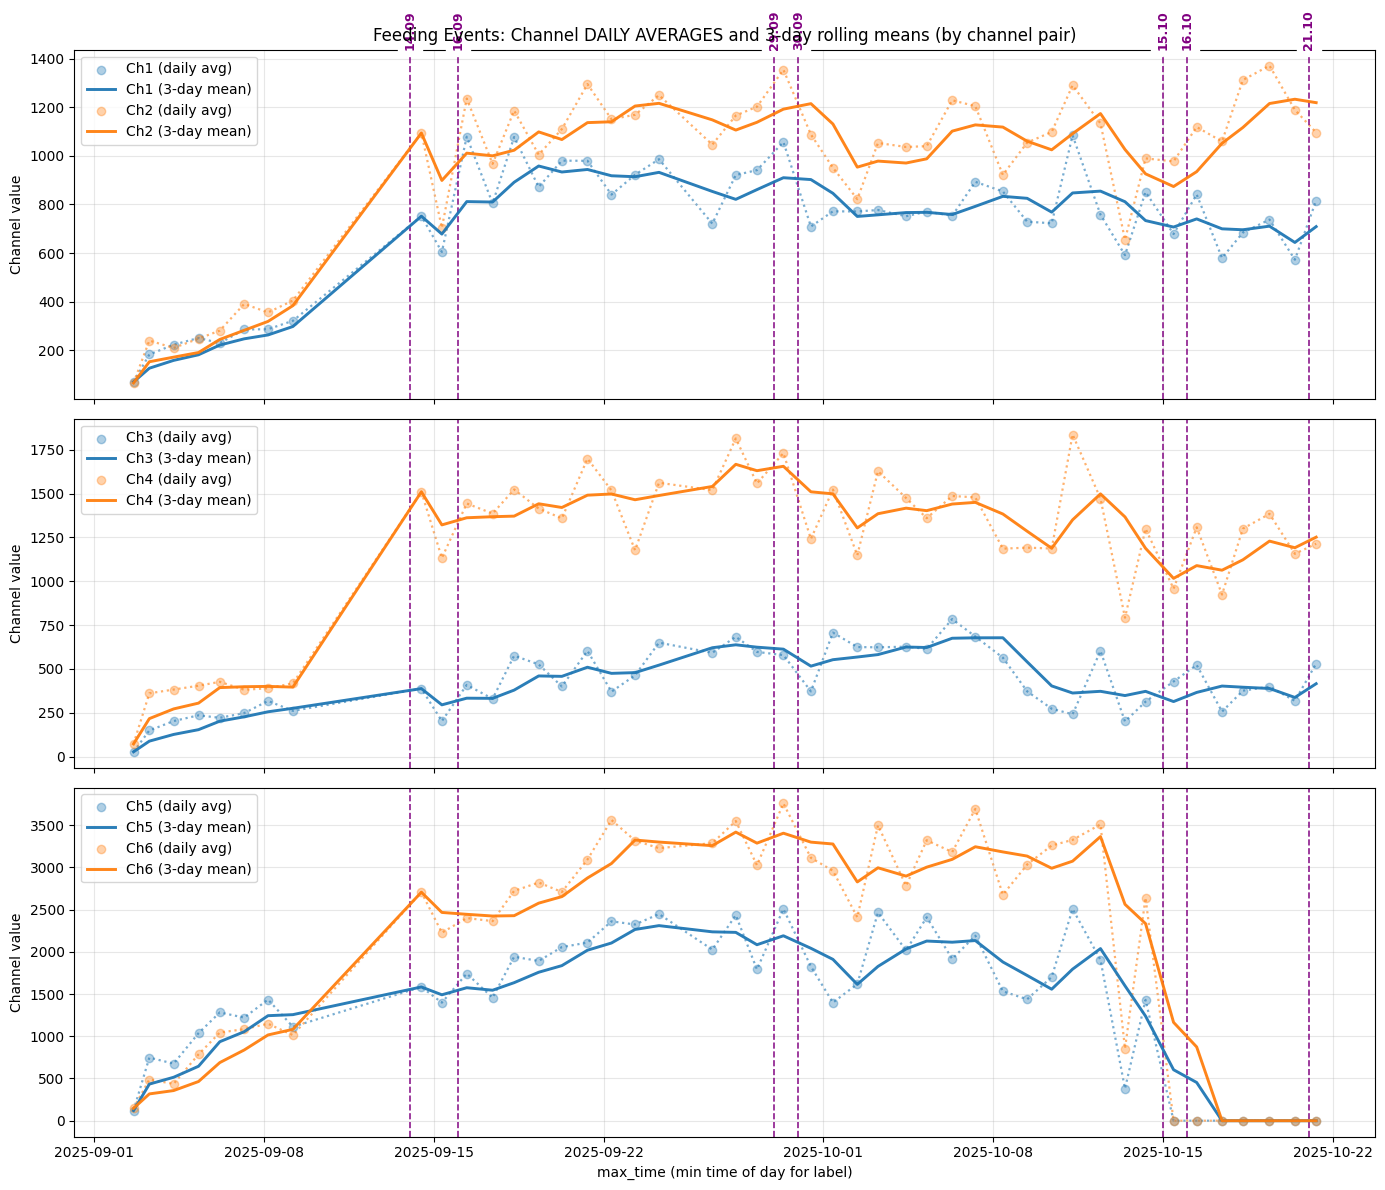

In [171]:
import matplotlib.pyplot as plt
import pandas as pd

# vline_labels and corresponding vline_dates are needed for annotation (from file context)
vline_labels = [
    "14.09",
    "16.09",
    "29.09",
    "30.09",
    "15.10",
    "16.10",
    "21.10"
]
from datetime import datetime

vline_dates = [
    pd.Timestamp("2025-09-14 00:00:00"),
    pd.Timestamp("2025-09-16 00:00:00"),
    pd.Timestamp("2025-09-29 00:00:00"),
    pd.Timestamp("2025-09-30 00:00:00"),
    pd.Timestamp("2025-10-15 00:00:00"),
    pd.Timestamp("2025-10-16 00:00:00"),
    pd.Timestamp("2025-10-21 00:00:00"),
]

# Load the data
df_feeding = pd.read_csv("feeding_values.csv", parse_dates=["max_time"])

# Cut out (set to NaN) values above 5900 for channel columns ("Ch1"-"Ch6" if present)
channel_cols = [col for col in df_feeding.columns if col.startswith("Ch")]
for col in channel_cols:
    df_feeding.loc[df_feeding[col] > 5900, col] = pd.NA

df_feeding['date'] = df_feeding['max_time'].dt.date

# This is the code as written (picks first value per day):
df_first_per_day = df_feeding.sort_values("max_time").groupby('date', as_index=False).first()

# --- To get the TRUE avg daily value for each channel, do this instead: ---
df_avg_per_day = df_feeding.groupby('date', as_index=False)[channel_cols].mean()
# For plotting, need a datetime index. Use the earliest max_time of each day as the time anchor.
min_times = df_feeding.groupby('date')['max_time'].min().values
df_avg_per_day['max_time'] = min_times
df_avg_per_day.set_index('max_time', inplace=True)

# Define channel groups for subplots
channel_groups = [
    ("Ch1", "Ch2"),
    ("Ch3", "Ch4"),
    ("Ch5", "Ch6"),
]

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

for i, (ax, group) in enumerate(zip(axes, channel_groups)):
    for col in group:
        if col in df_avg_per_day.columns:
            # get color for consistency between scatter and lines
            color = ax._get_lines.get_next_color() if hasattr(ax._get_lines, "get_next_color") else None

            # Plot the daily (avg) value as dots
            ax.scatter(
                df_avg_per_day.index,
                df_avg_per_day[col],
                marker='o',
                label=f"{col} (daily avg)",
                alpha=0.35,  # Slightly more visible dots
                color=color,
                zorder=2,
            )
            # Connect the dots with a dotted line
            ax.plot(
                df_avg_per_day.index,
                df_avg_per_day[col],
                linestyle=":",
                color=color,
                alpha=0.6,
                zorder=1,
                linewidth=1.6,
                label=None
            )
            # Solid line for the 3-day rolling mean
            roll_mean = df_avg_per_day[col].rolling(window='3D', min_periods=1).mean()
            ax.plot(
                df_avg_per_day.index,
                roll_mean,
                linestyle="-",    # Solid line
                linewidth=2.1,
                label=f"{col} (3-day mean)",
                zorder=3,
                color=color,
                alpha=0.95
            )
    # Draw vertical lines for significant (feeding) events
    for vld, vll in zip(vline_dates, vline_labels):
        ax.axvline(vld, color="purple", linestyle="--", linewidth=1.2, alpha=0.9)
        # Only annotate on first axis to avoid clutter
        if i == 0:
            ax.text(vld, ax.get_ylim()[1], vll, color="purple", rotation=90,
                    va='bottom', ha='center', fontsize=9, fontweight='bold',
                    backgroundcolor="white")
    ax.set_ylabel("Channel value")
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("max_time (min time of day for label)")
axes[0].set_title("Feeding Events: Channel DAILY AVERAGES and 3-day rolling means (by channel pair)")
plt.tight_layout()
plt.show()


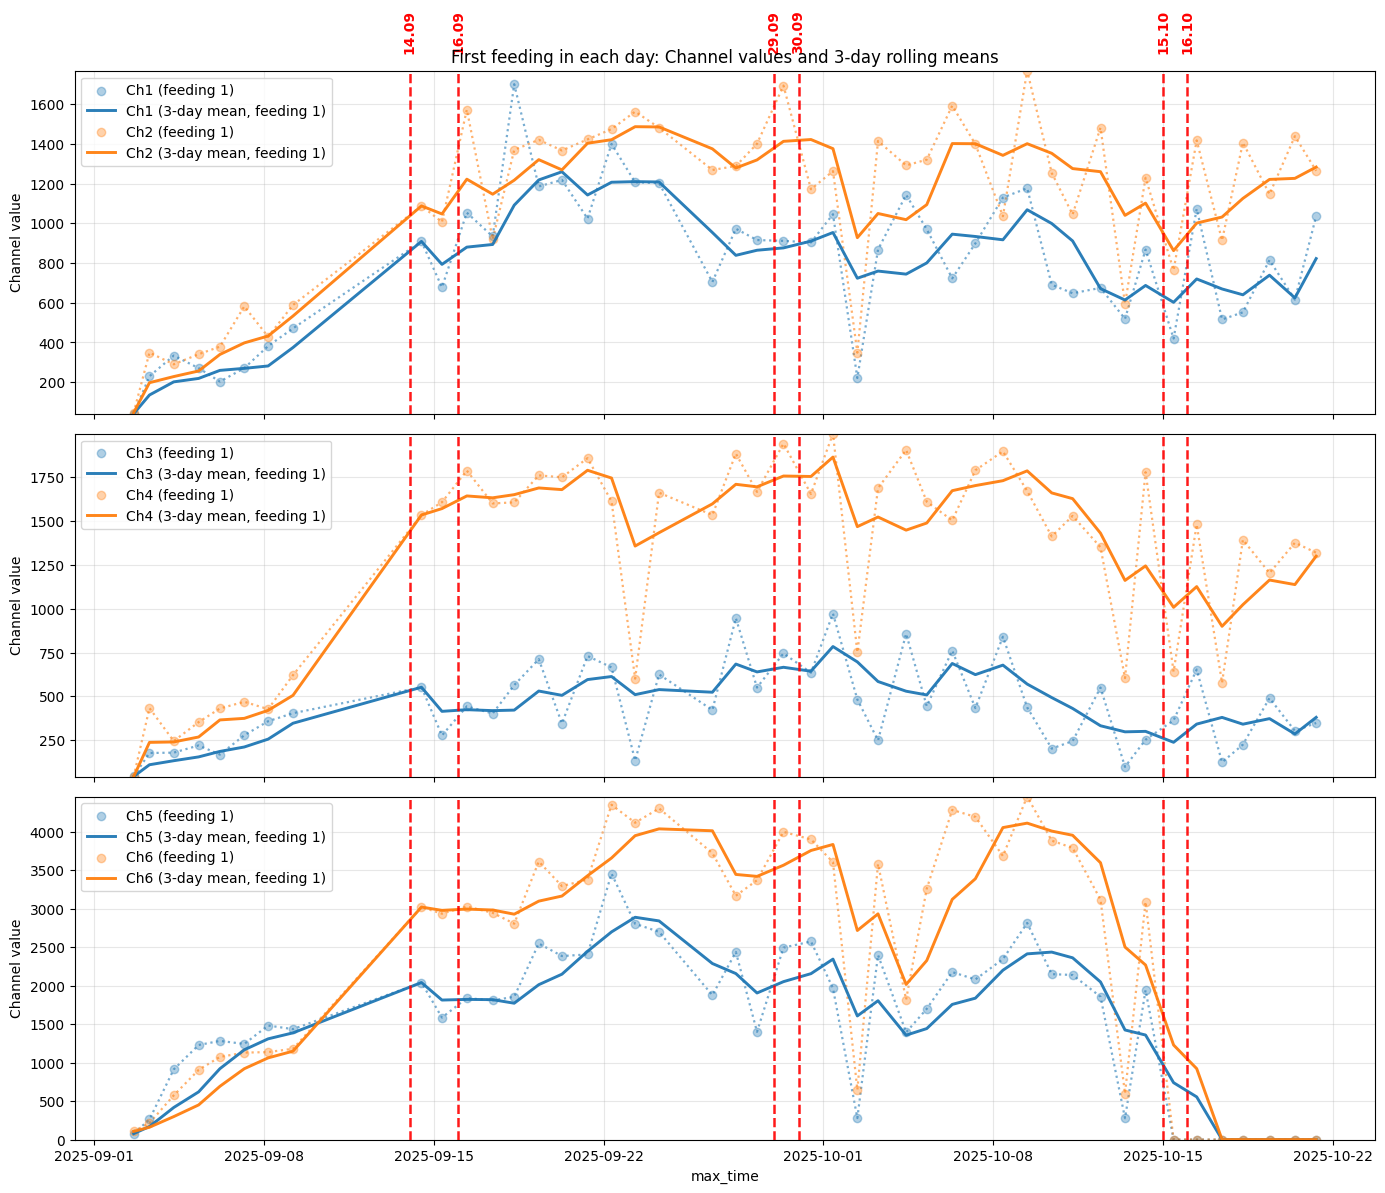

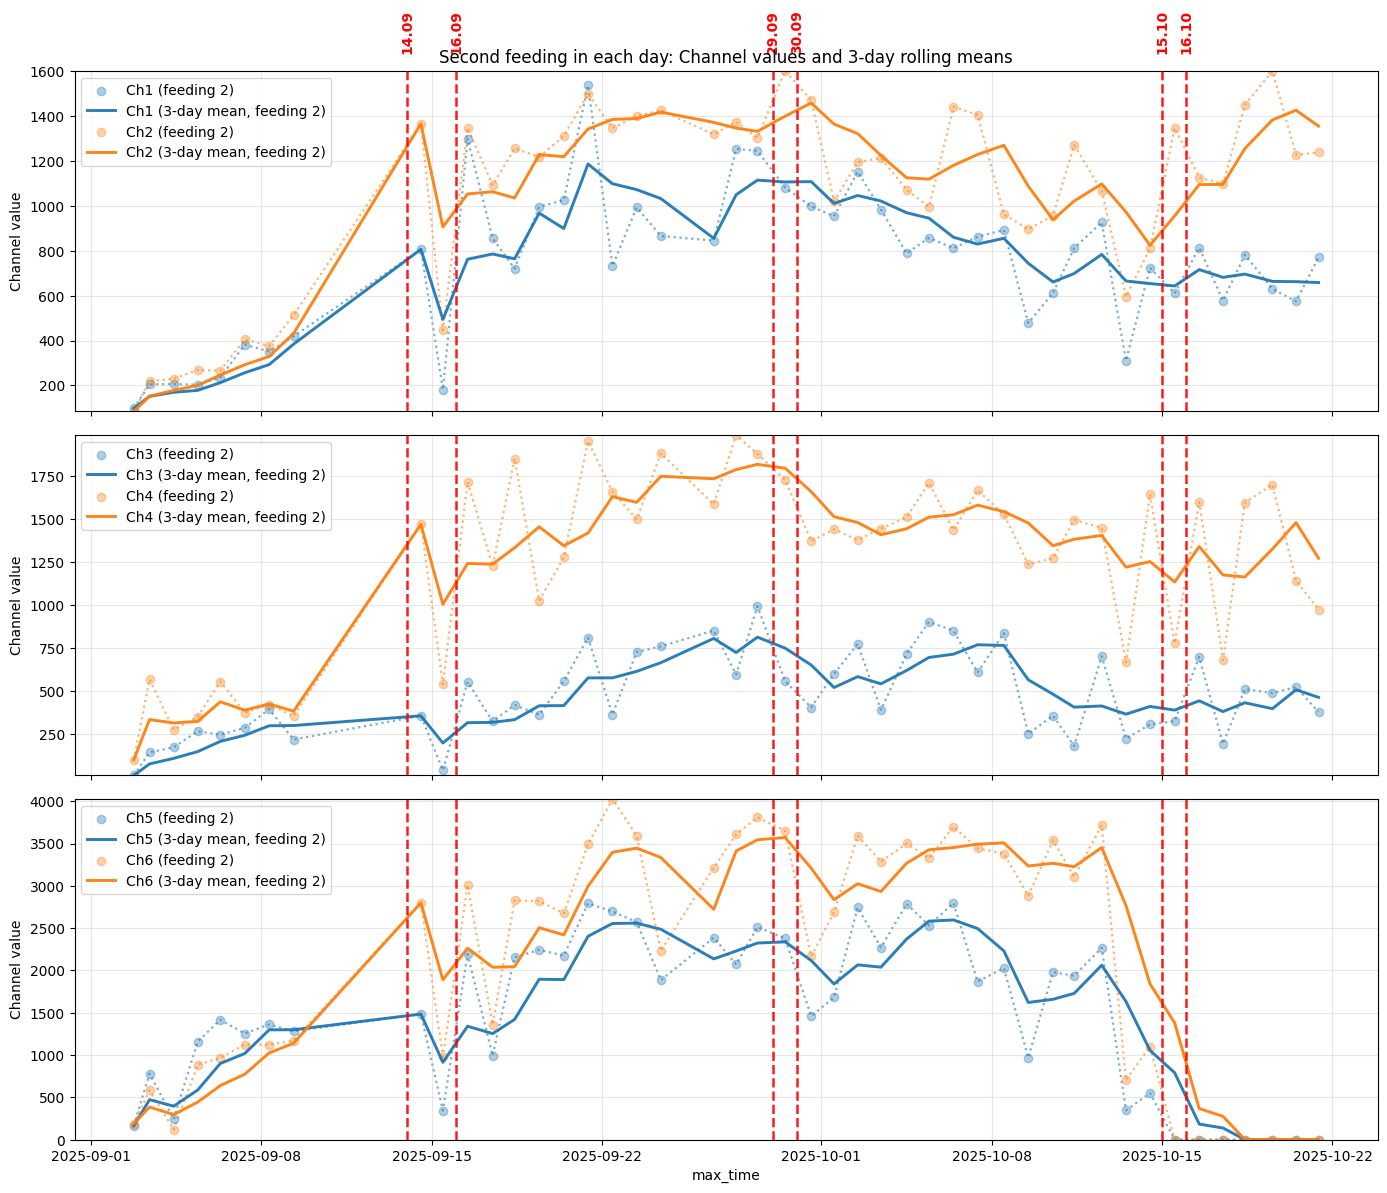

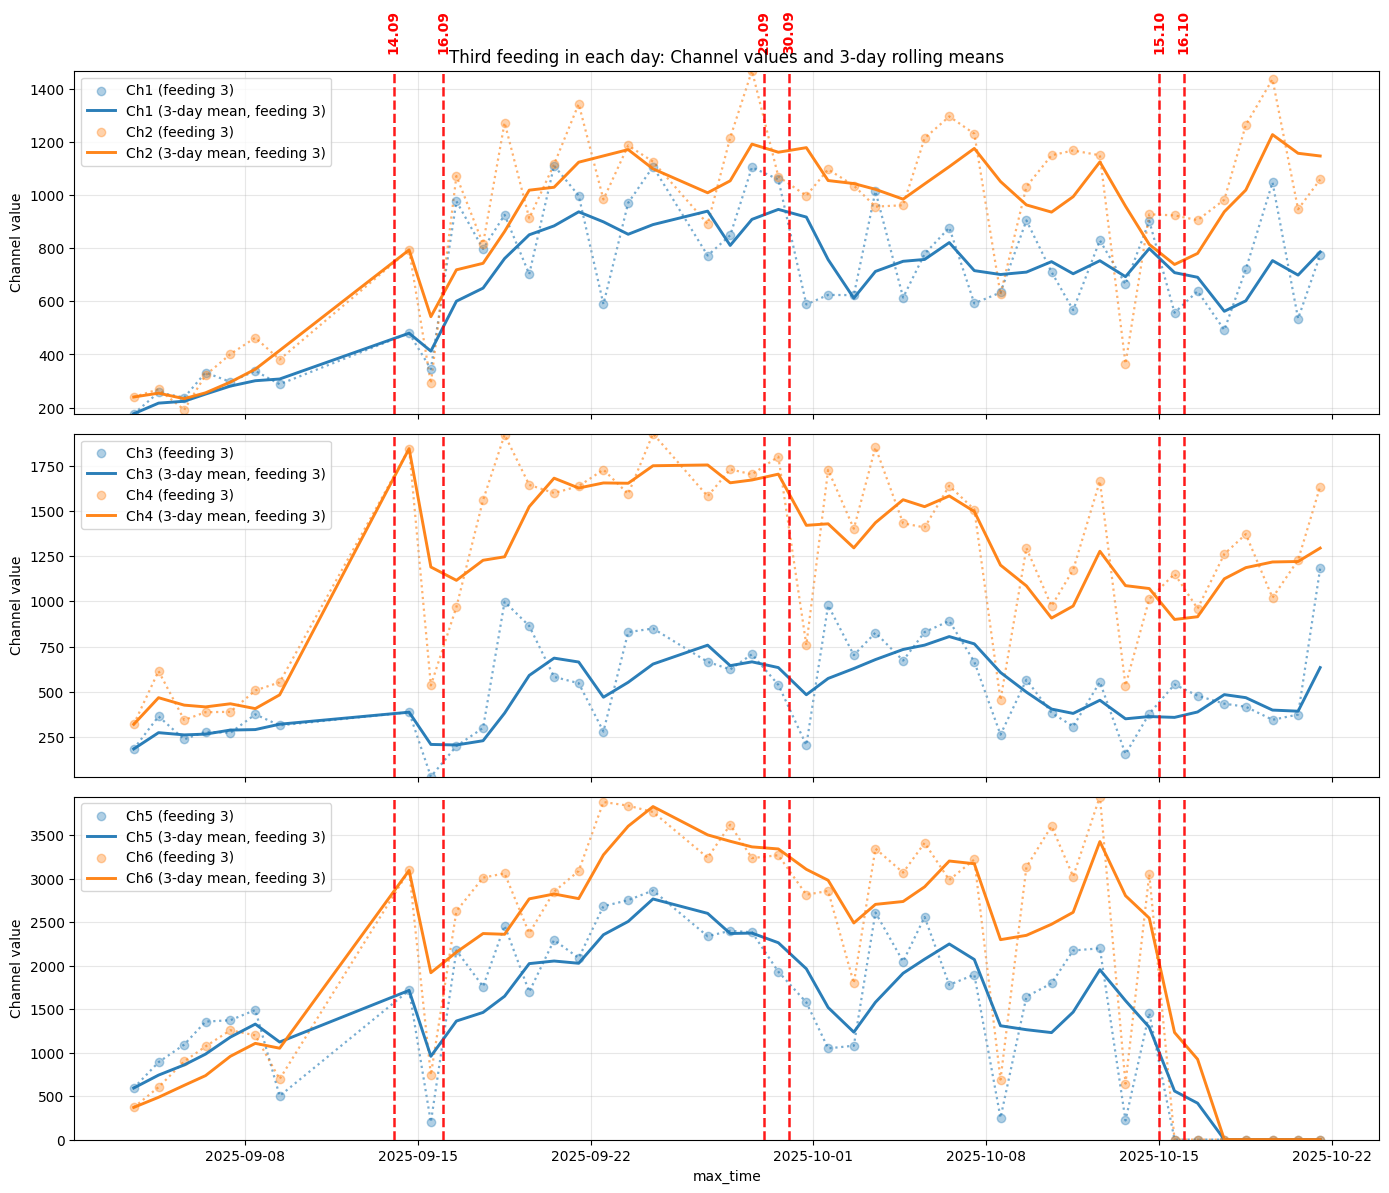

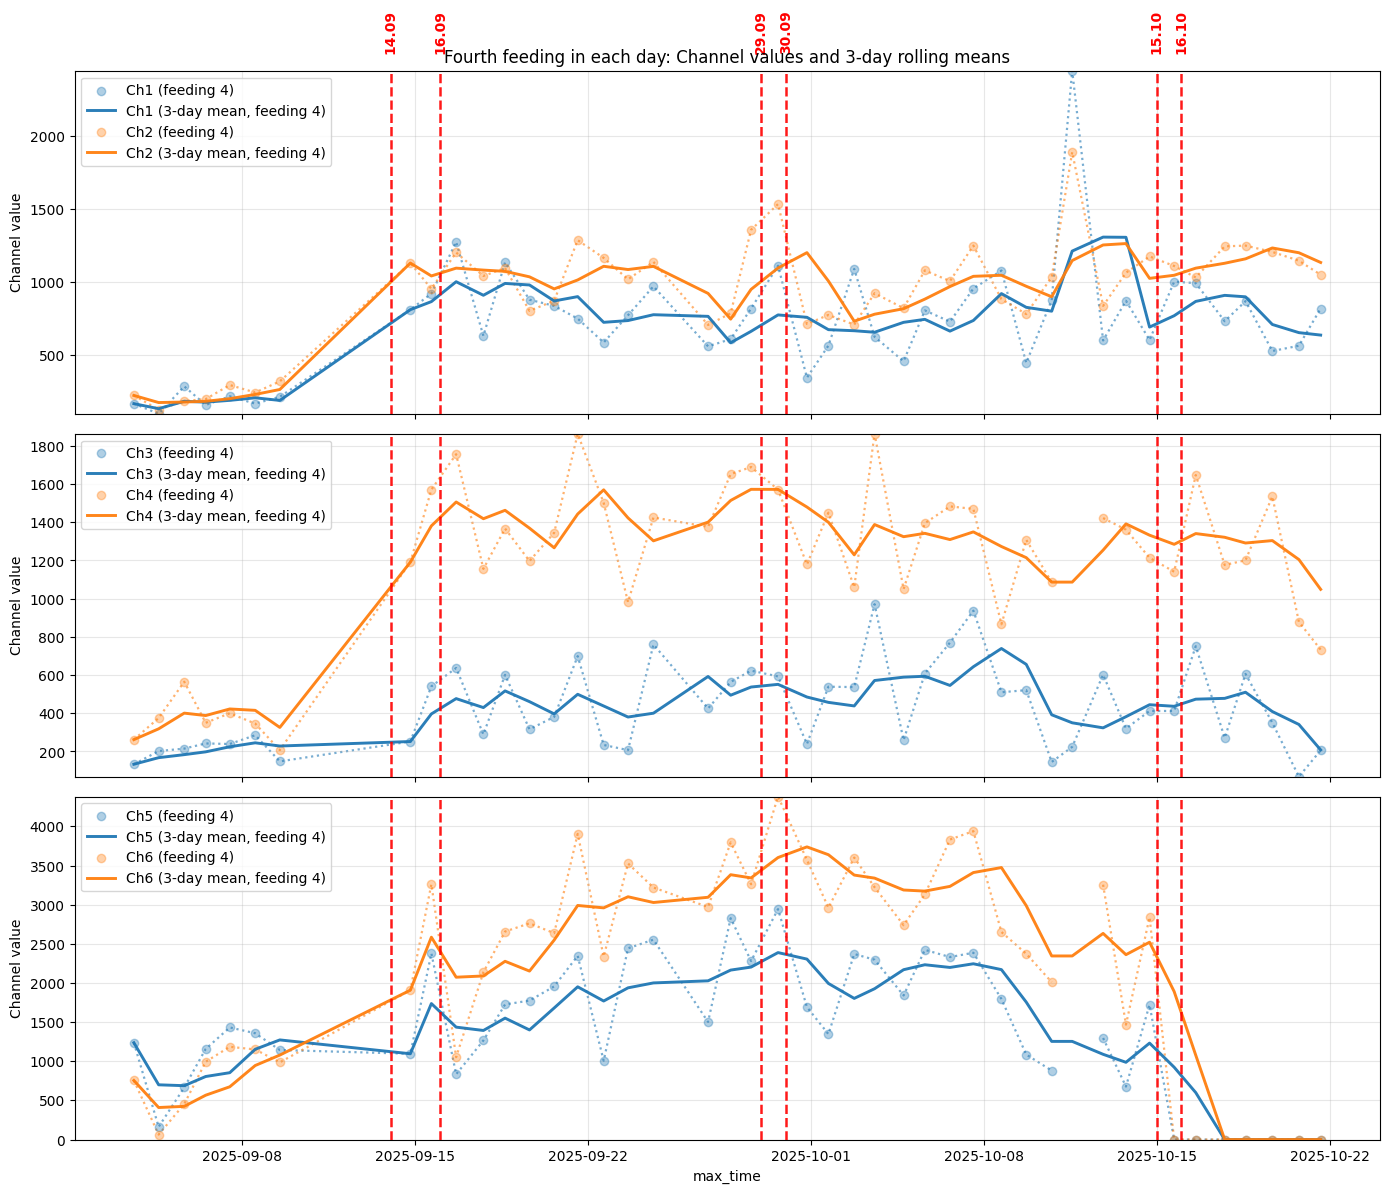

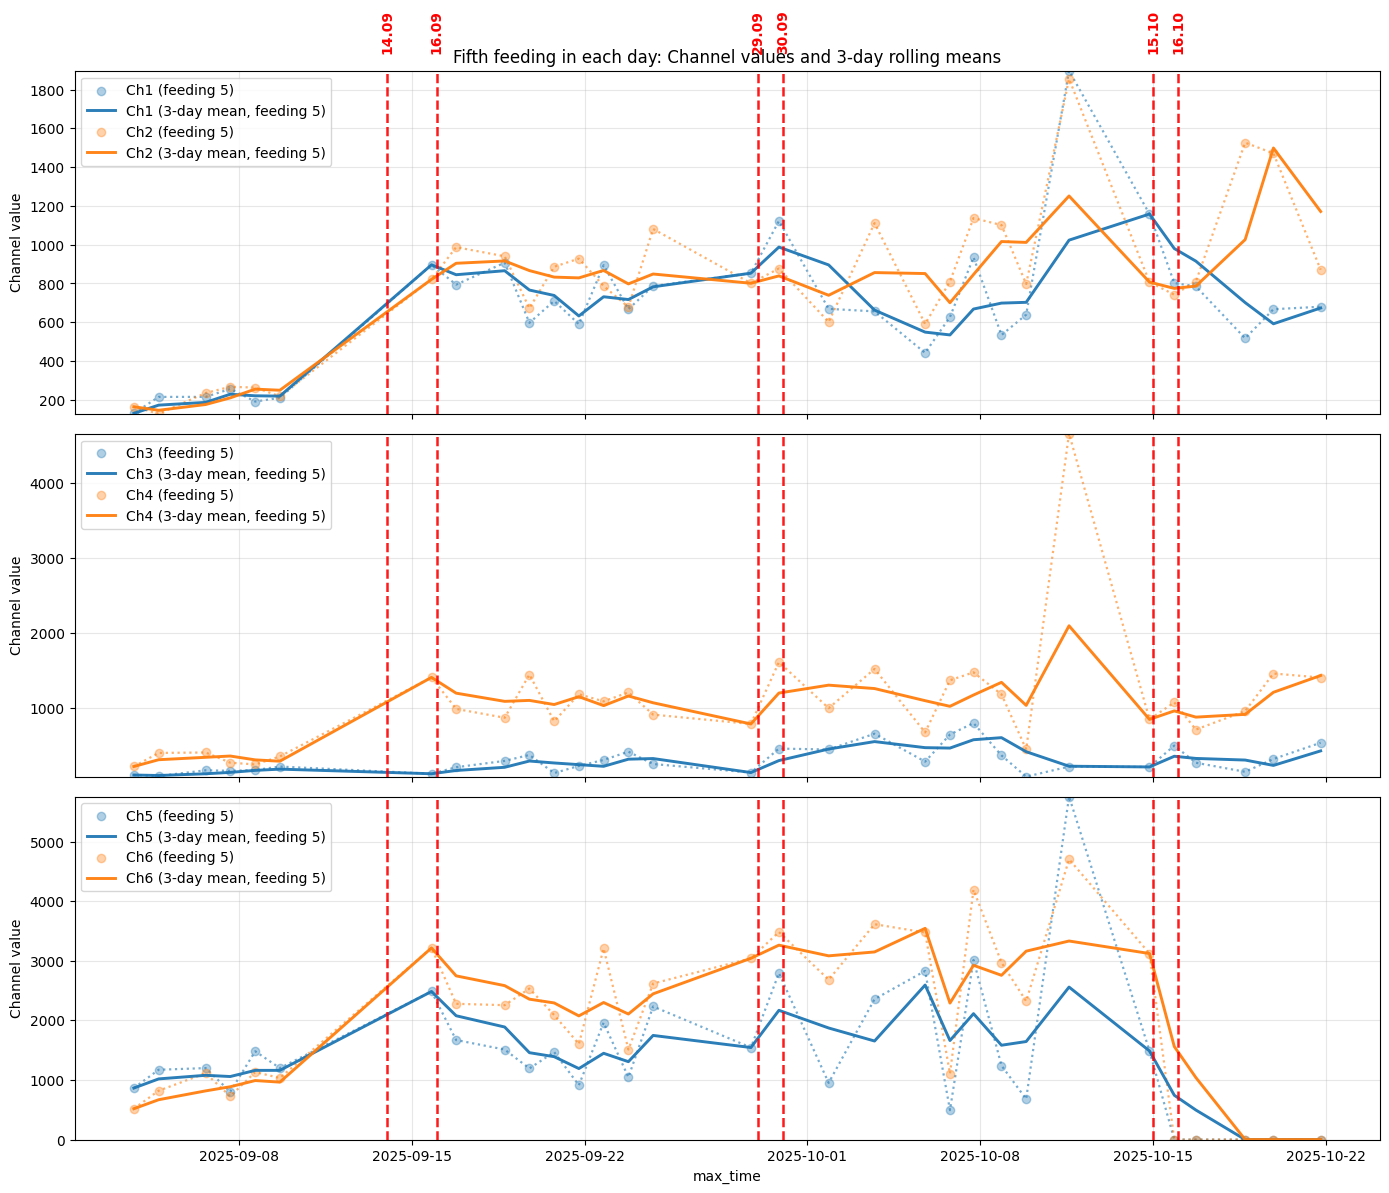

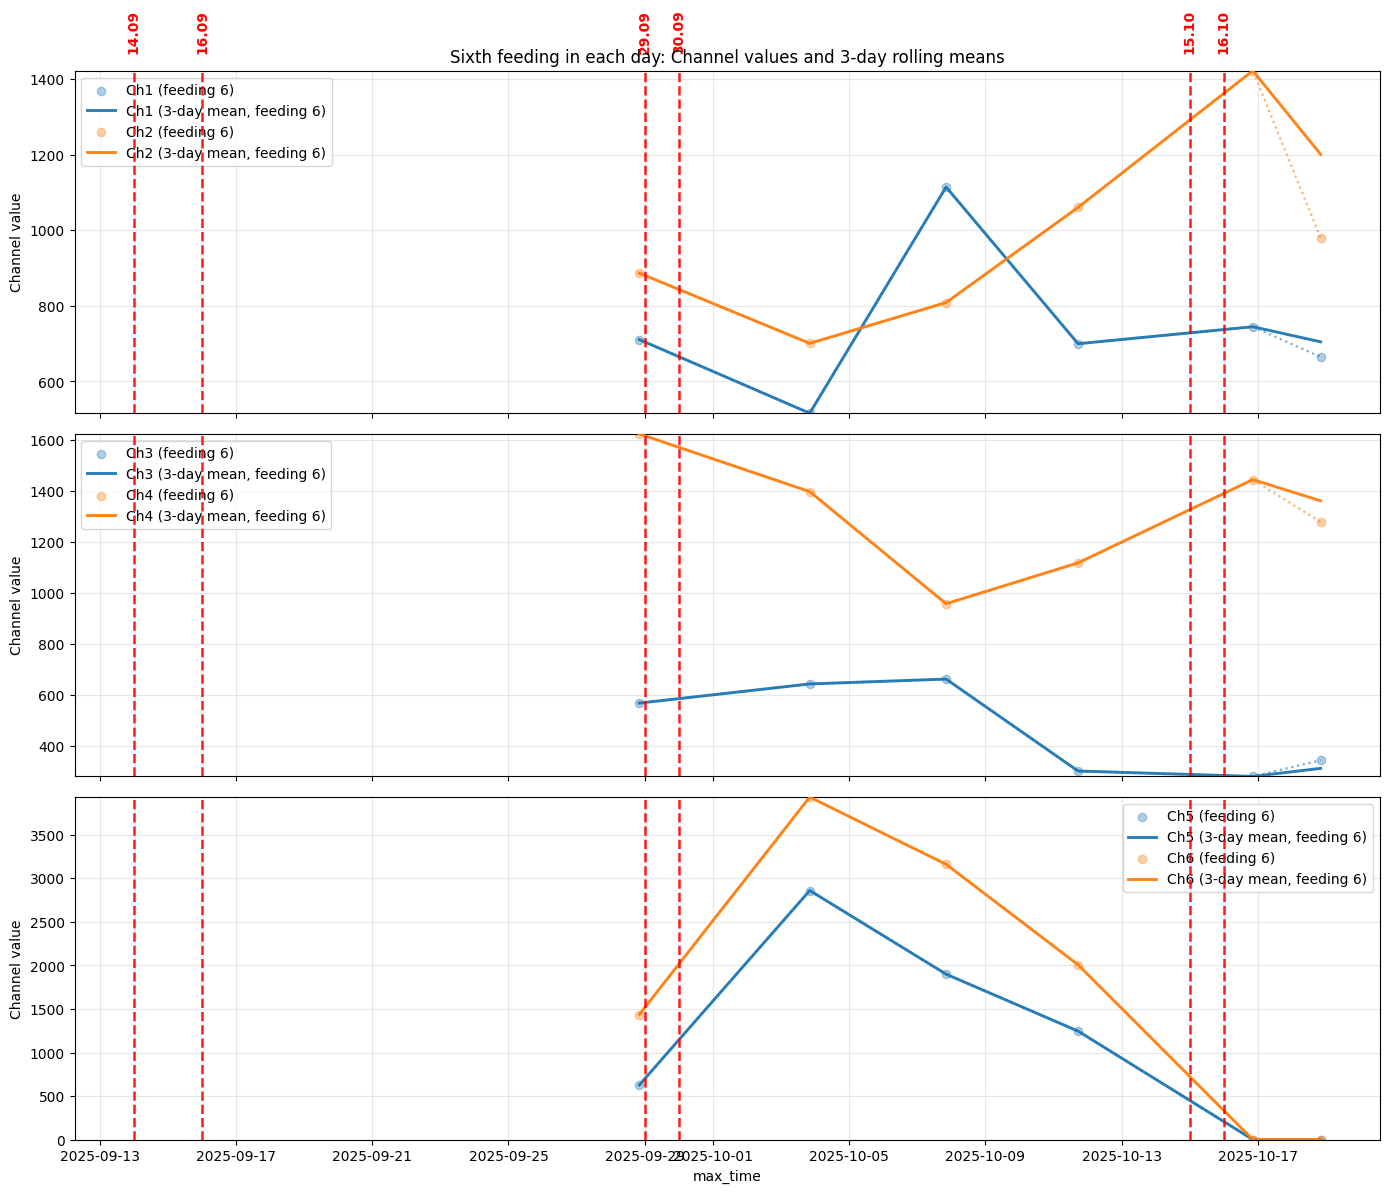

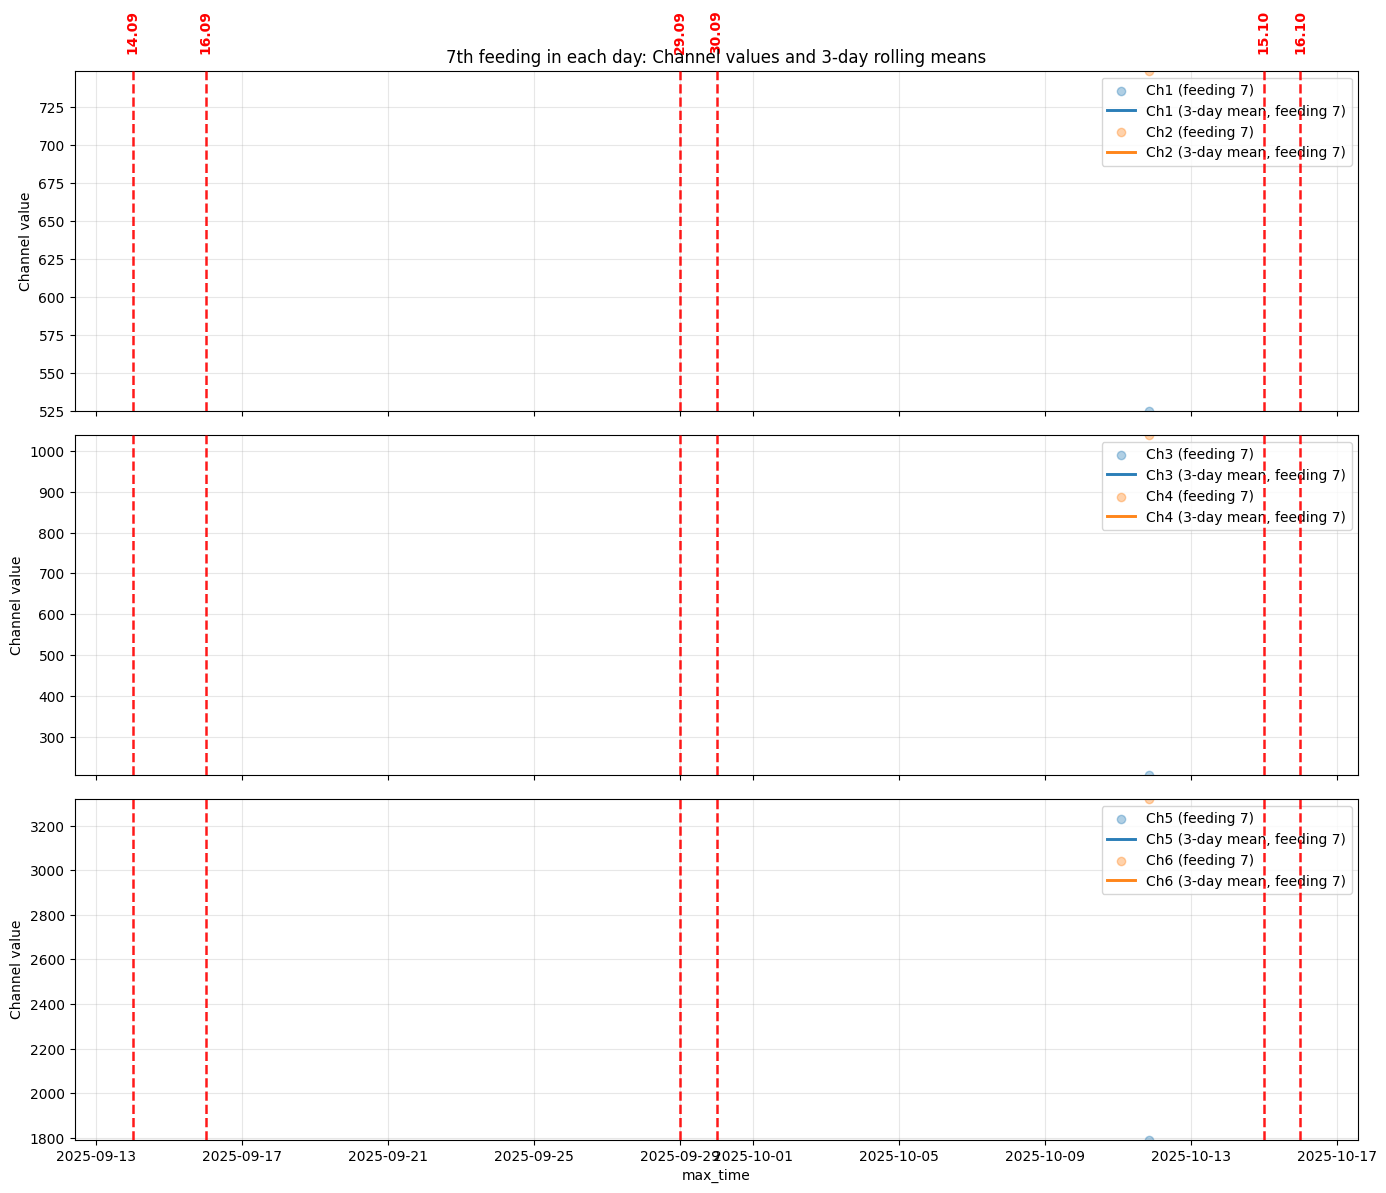

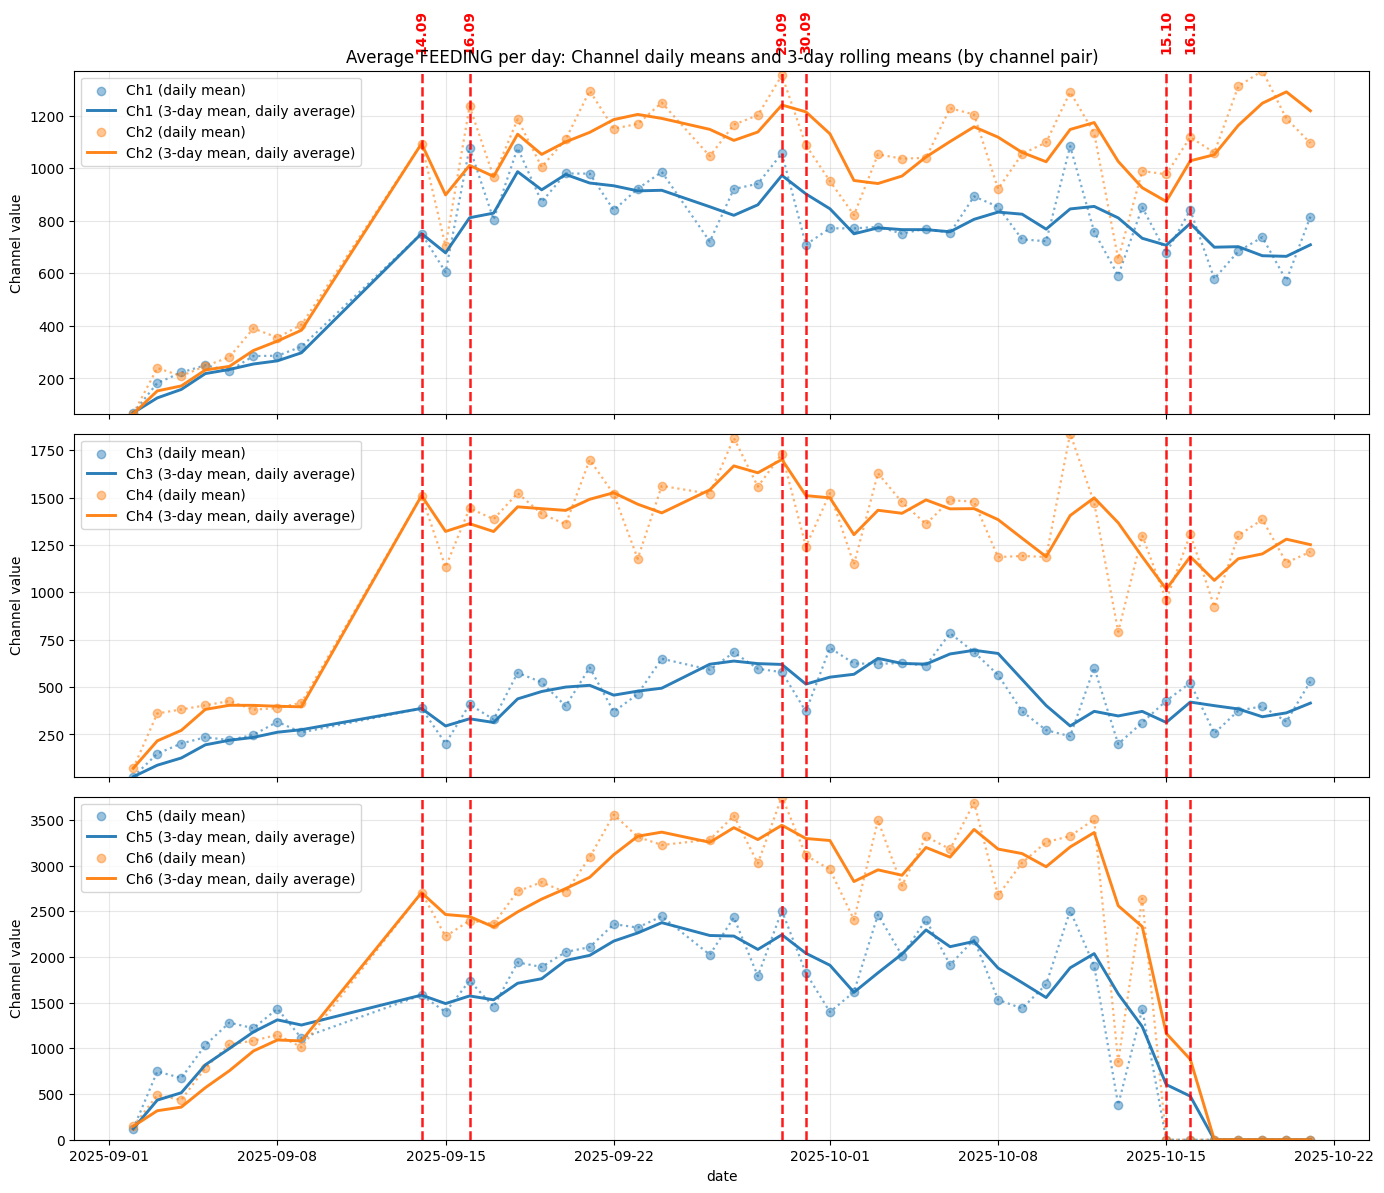

In [100]:
import matplotlib.pyplot as plt
import pandas as pd

# Define the stress events as datetime (for red vertical lines)
stress_event_dates = [
    "2025-09-14",
    "2025-09-16",
    "2025-09-29",
    "2025-09-30",
    "2025-10-15",
    "2025-10-16"
]
stress_event_labels = [
    "14.09",
    "16.09",
    "29.09",
    "30.09",
    "15.10",
    "16.10"
]
# Convert to pandas Timestamp for comparison with index (assumed to be in the same year as your data, e.g. 2025)
stress_events = [pd.to_datetime(d) for d in stress_event_dates]

# Load the data
df_feeding = pd.read_csv("feeding_values.csv", parse_dates=["max_time"])
channel_cols = [col for col in df_feeding.columns if col.startswith("Ch")]

# Clean values above 5900
for col in channel_cols:
    df_feeding.loc[df_feeding[col] > 5900, col] = pd.NA

df_feeding['date'] = df_feeding['max_time'].dt.date

# Sort so that groupby(...).nth(idx) gets the earliest/second... feeding per day
df_feeding_sorted = df_feeding.sort_values("max_time")

# Find out the max number of feedings per day across all data
feedings_per_day = df_feeding_sorted.groupby('date').size()
max_feedings = feedings_per_day.max()

# Define channel groups for subplots
channel_groups = [
    ("Ch1", "Ch2"),
    ("Ch3", "Ch4"),
    ("Ch5", "Ch6"),
]

# For "feeding_number" = first, second, ... per day, make a plot for each
for feeding_number in range(max_feedings):
    # For each day, pick the Nth feeding (0=first, 1=second, ...)
    df_this = (
        df_feeding_sorted
        .groupby('date', as_index=False)
        .nth(feeding_number)
        .dropna(subset=['max_time'])
    )

    # If nothing on this feeding_number, skip
    if df_this.empty:
        continue

    # Set time as index
    df_this = df_this.set_index('max_time')

    # Prepare figure
    fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
    for i, (ax, group) in enumerate(zip(axes, channel_groups)):
        # Compute dynamic y-limits for this subplot only across shown channels
        local_min, local_max = None, None
        cols_in_data = [col for col in group if col in df_this.columns]
        for col in cols_in_data:
            col_min = df_this[col].min(skipna=True)
            col_max = df_this[col].max(skipna=True)
            if local_min is None or (pd.notna(col_min) and col_min < local_min):
                local_min = col_min
            if local_max is None or (pd.notna(col_max) and col_max > local_max):
                local_max = col_max
        if local_min is None:
            local_min = 0
        if local_max is None:
            local_max = 1

        for col in group:
            if col in df_this.columns:
                color = ax._get_lines.get_next_color() if hasattr(ax._get_lines, "get_next_color") else None

                # Dots: feeding value
                ax.scatter(
                    df_this.index,
                    df_this[col],
                    marker='o',
                    label=f"{col} (feeding {feeding_number+1})",
                    alpha=0.35,
                    color=color,
                    zorder=2,
                )
                # Connect dots
                ax.plot(
                    df_this.index,
                    df_this[col],
                    linestyle=":",
                    color=color,
                    alpha=0.6,
                    zorder=1,
                    linewidth=1.6,
                    label=None
                )
                # Solid line for 3-day rolling mean for this feeding order
                roll_mean = df_this[col].rolling(window='3D', min_periods=1).mean()
                ax.plot(
                    df_this.index,
                    roll_mean,
                    linestyle="-",
                    linewidth=2.1,
                    label=f"{col} (3-day mean, feeding {feeding_number+1})",
                    zorder=3,
                    color=color,
                    alpha=0.95
                )
        # Draw vertical red lines for stress events
        for red_idx, (event_date, event_label) in enumerate(zip(stress_events, stress_event_labels)):
            ax.axvline(event_date, color="red", linestyle="--", linewidth=1.8, alpha=0.9, zorder=10)
            # Only label on the first axis of the 3 subplots to avoid clutter
            if i == 0:
                ax.text(event_date, ax.get_ylim()[1], event_label, color="red", rotation=90,
                        va='bottom', ha='center', fontsize=10, fontweight='bold',
                        backgroundcolor="white")
        # Set the local y-limits for this plot
        ax.set_ylim(local_min, local_max)
        ax.set_ylabel("Channel value")
        ax.legend()
        ax.grid(True, alpha=0.3)

    axes[-1].set_xlabel("max_time")
    suffixes = ["first", "second", "third", "fourth", "fifth", "sixth"]
    if feeding_number < len(suffixes):
        ordinal = suffixes[feeding_number]
    else:
        ordinal = f"{feeding_number+1}th"
    axes[0].set_title(f"{ordinal.capitalize()} feeding in each day: Channel values and 3-day rolling means")
    plt.tight_layout()
    plt.show()

# --- Plot the average of all feedings for each day ---
# Group by date and calculate mean for each channel
df_avg_per_day = (
    df_feeding
    .groupby('date')[channel_cols]
    .mean()
)

# Create a time index from the date field for plotting
df_avg_per_day.index = pd.to_datetime(df_avg_per_day.index)

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
for i, (ax, group) in enumerate(zip(axes, channel_groups)):
    # Get valid columns
    cols_in_data = [col for col in group if col in df_avg_per_day.columns]
    # Dynamic y-limits for this subplot
    local_min, local_max = None, None
    for col in cols_in_data:
        col_min = df_avg_per_day[col].min(skipna=True)
        col_max = df_avg_per_day[col].max(skipna=True)
        if local_min is None or (pd.notna(col_min) and col_min < local_min):
            local_min = col_min
        if local_max is None or (pd.notna(col_max) and col_max > local_max):
            local_max = col_max
    if local_min is None:
        local_min = 0
    if local_max is None:
        local_max = 1
    for col in group:
        if col in df_avg_per_day.columns:
            color = ax._get_lines.get_next_color() if hasattr(ax._get_lines, "get_next_color") else None
            # Dots and dashed for daily average
            ax.scatter(
                df_avg_per_day.index,
                df_avg_per_day[col],
                marker='o',
                label=f"{col} (daily mean)",
                alpha=0.45,
                color=color,
                zorder=2,
            )
            ax.plot(
                df_avg_per_day.index,
                df_avg_per_day[col],
                linestyle=":",
                color=color,
                alpha=0.6,
                zorder=1,
                linewidth=1.6,
                label=None
            )
            # Solid line for 3-day rolling mean of daily averages
            roll_mean = df_avg_per_day[col].rolling(window='3D', min_periods=1).mean()
            ax.plot(
                df_avg_per_day.index,
                roll_mean,
                linestyle="-",
                linewidth=2.1,
                label=f"{col} (3-day mean, daily average)",
                zorder=3,
                color=color,
                alpha=0.95
            )
    # Draw vertical red lines for stress events
    for red_idx, (event_date, event_label) in enumerate(zip(stress_events, stress_event_labels)):
        ax.axvline(event_date, color="red", linestyle="--", linewidth=1.8, alpha=0.9, zorder=10)
        if i == 0:
            ax.text(event_date, ax.get_ylim()[1], event_label, color="red", rotation=90,
                    va='bottom', ha='center', fontsize=10, fontweight='bold',
                    backgroundcolor="white")
    ax.set_ylim(local_min, local_max)
    ax.set_ylabel("Channel value")
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("date")
axes[0].set_title("Average FEEDING per day: Channel daily means and 3-day rolling means (by channel pair)")
plt.tight_layout()
plt.show()

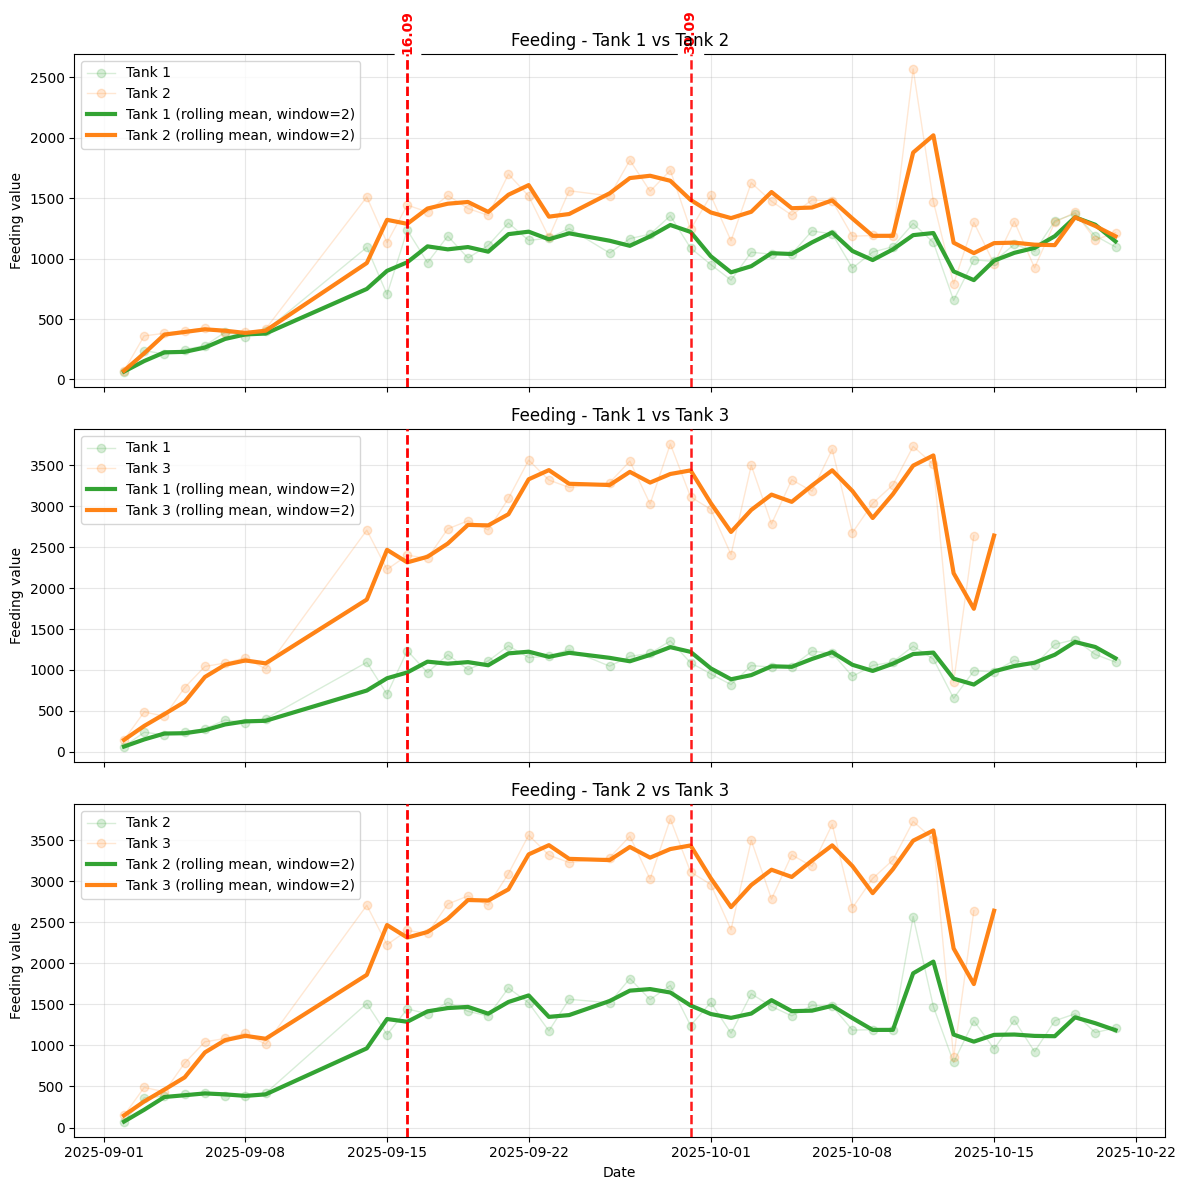

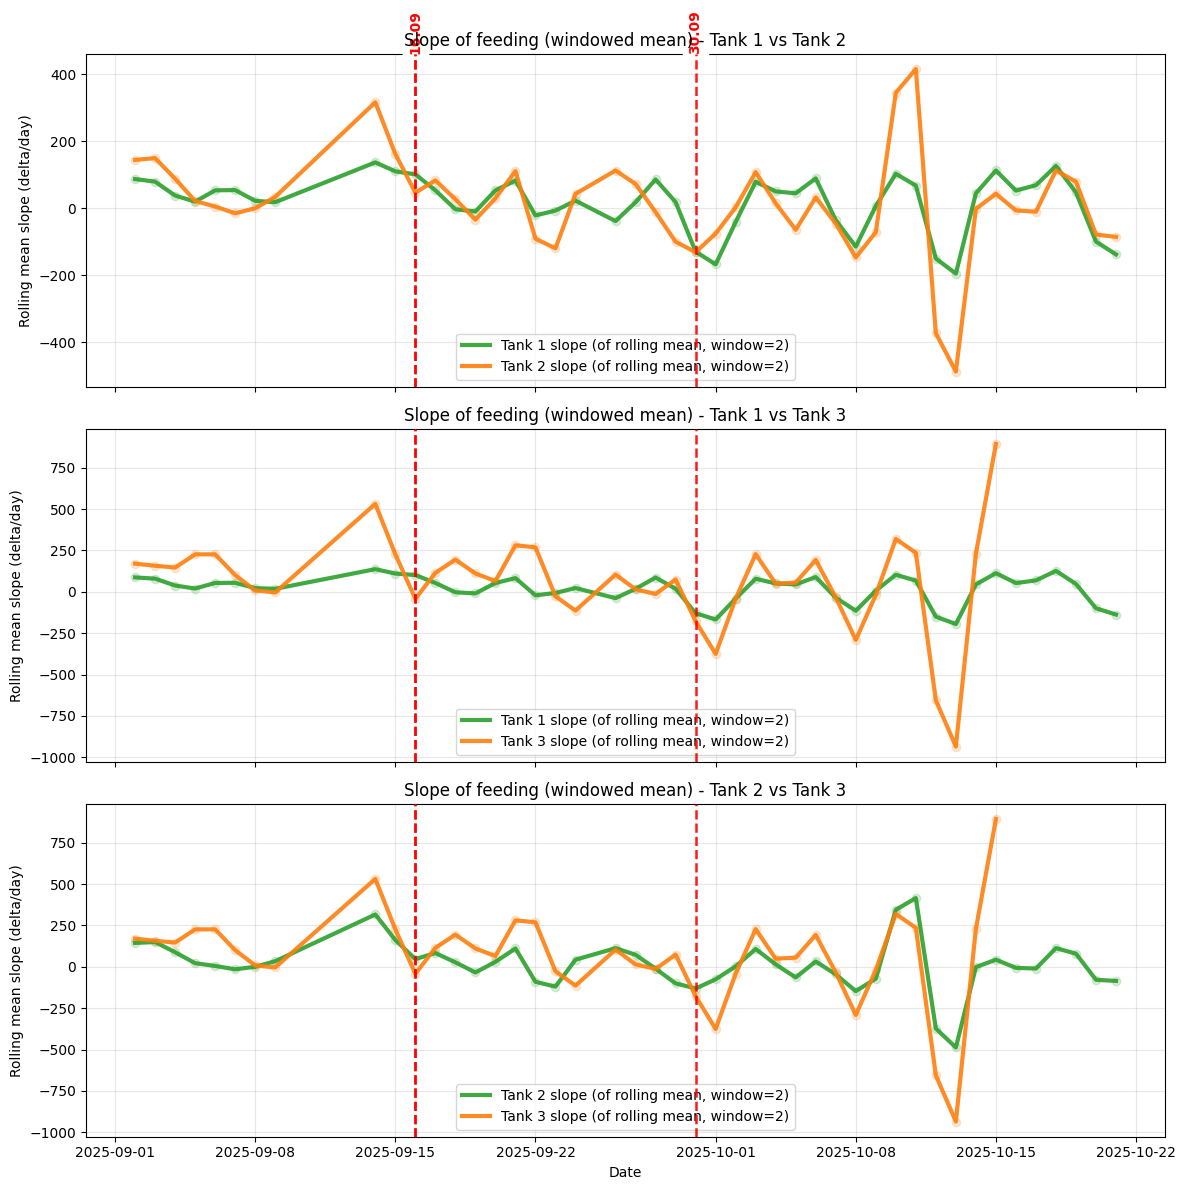

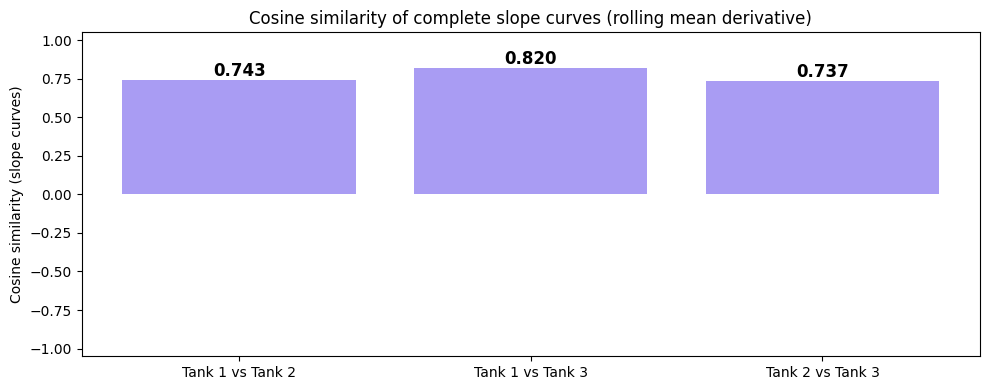

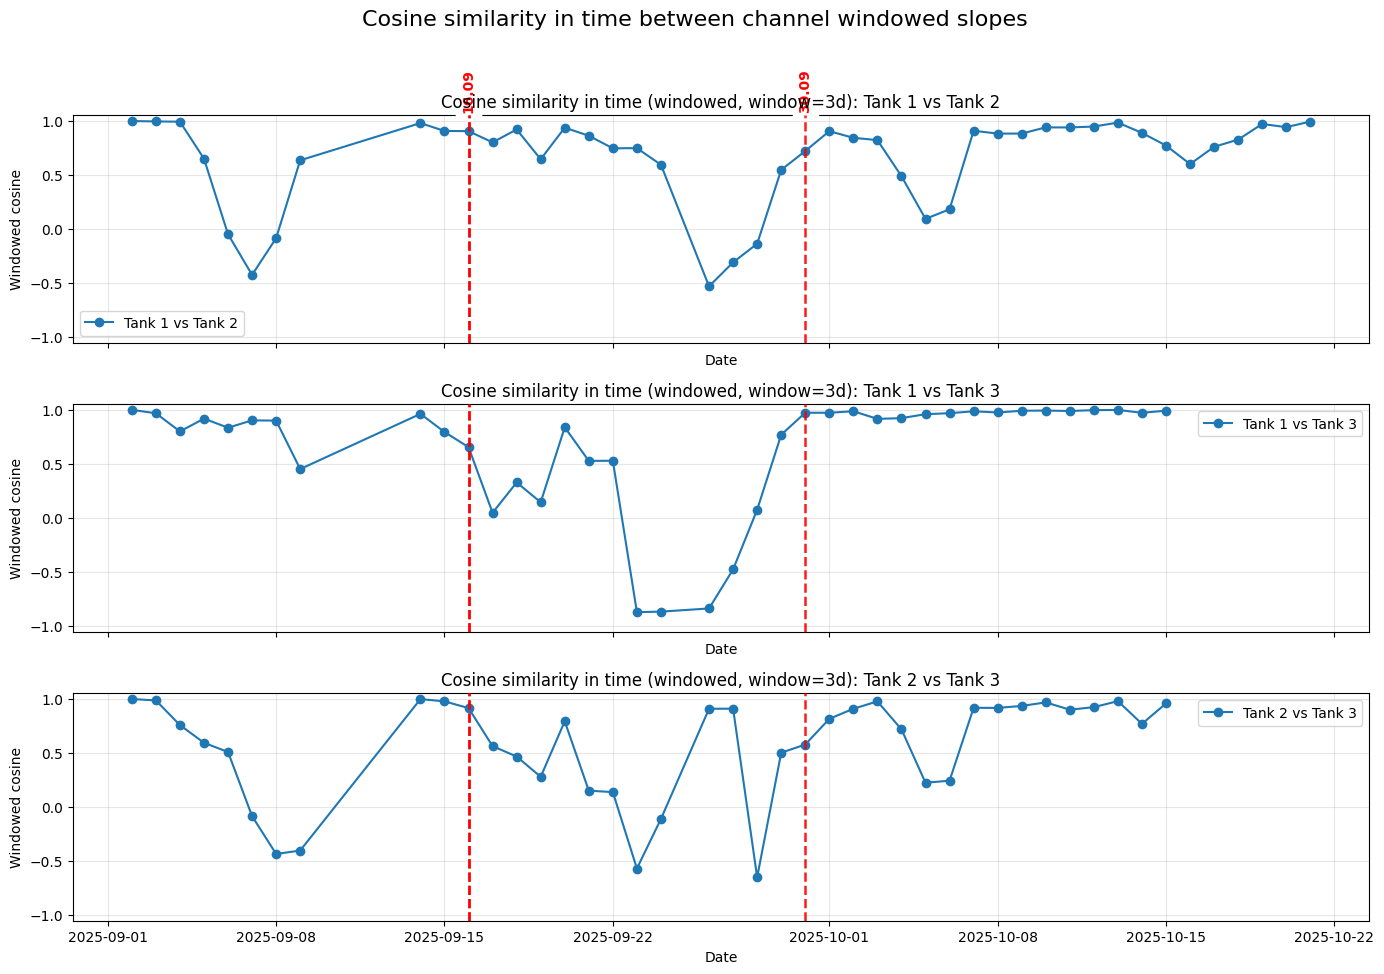

In [153]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Ch2 is tank 1, Ch4 is tank 2, Ch6 is tank 3
channel_labels = {
    "Ch2": "Tank 1",
    "Ch4": "Tank 2",
    "Ch6": "Tank 3"
}

# Load the feeding values CSV
df = pd.read_csv('feeding_values.csv', parse_dates=['max_time'])
df.set_index('max_time', inplace=True)

# Only keep Ch2, Ch4, Ch6
channel_cols = ["Ch2", "Ch4", "Ch6"]
df = df[channel_cols]

# Resample to daily means only for dates with any value (skip days with all NaN)
df_daily = df.resample('D').mean()
df_daily = df_daily.dropna(how='all')  # Remove days with all NaN

# For tank 3 (Ch6), show feeding values only up to and including 12.10 (October 12th) for every year
if pd.api.types.is_datetime64_any_dtype(df_daily.index):
    # This mask is True for dates up to and including October 12 (month==10 and day<=12, or month<10)
    mask_ch6 = (df_daily.index.month < 10) | ((df_daily.index.month == 10) & (df_daily.index.day <= 14))
    df_daily_plot = df_daily.copy()
    df_daily_plot.loc[~mask_ch6, "Ch6"] = np.nan
else:
    df_daily_plot = df_daily

window = 2  # Example: Change this to 3 or other integer if you want

# List pairs of tanks to compare
col_pairs = []
for i, col1 in enumerate(channel_cols):
    for j, col2 in enumerate(channel_cols):
        if i < j:
            col_pairs.append((col1, col2))

# Define vertical line dates: 16.09, 30.09, and another 16.09 (for multiple years if exists, follows user prompt)
# We'll try to mark 16 September of every year in the data, 30 September of every year, and another 16 September if that's what the user means.
unique_years = sorted(set(df_daily_plot.index.year))
vertline_dates = []
for y in unique_years:
    try:
        # 16 Sep
        vertline_dates.append(pd.Timestamp(year=y, month=9, day=16))
        # 30 Sep
        vertline_dates.append(pd.Timestamp(year=y, month=9, day=30))
        # Another 16 Sep (the user listed twice; just repeat or add for next year)
        vertline_dates.append(pd.Timestamp(year=y, month=9, day=16))
    except Exception:
        pass

# ==========
# 1. Original Sample Plot: Channel daily values and rolling means
# ==========

fig, axes = plt.subplots(len(col_pairs), 1, figsize=(12, 4 * len(col_pairs)), sharex=True)
if len(col_pairs) == 1:
    axes = np.array([axes])

for row_idx, (col1, col2) in enumerate(col_pairs):
    ax = axes[row_idx]
    # Plot daily feeding values for both tanks -- make these transparent (faint)
    ax.plot(
        df_daily_plot.index, 
        df_daily_plot[col1], 
        marker='o', 
        color='tab:green', 
        label=f"{channel_labels[col1]}",
        alpha=0.18,                # More transparent points
        linewidth=1
    )
    ax.plot(
        df_daily_plot.index, 
        df_daily_plot[col2], 
        marker='o', 
        color='tab:orange', 
        label=f"{channel_labels[col2]}",
        alpha=0.18,                # More transparent points
        linewidth=1
    )
    # Plot rolling means, as strong (opaque, thicker)
    roll_mean1 = df_daily_plot[col1].rolling(window=window, min_periods=1).mean()
    roll_mean2 = df_daily_plot[col2].rolling(window=window, min_periods=1).mean()
    ax.plot(
        df_daily_plot.index, 
        roll_mean1, 
        linestyle='-', 
        linewidth=3, 
        color='tab:green', 
        alpha=0.97,             # Strong/opaque line
        label=f"{channel_labels[col1]} (rolling mean, window={window})"
    )
    ax.plot(
        df_daily_plot.index, 
        roll_mean2, 
        linestyle='-', 
        linewidth=3, 
        color='tab:orange', 
        alpha=0.97,             # Strong/opaque line
        label=f"{channel_labels[col2]} (rolling mean, window={window})"
    )

    # Add red vertical lines & labels 
    y_min, y_max = ax.get_ylim()
    for n, vdate in enumerate(vertline_dates):
        if vdate >= df_daily_plot.index.min() and vdate <= df_daily_plot.index.max():
            ax.axvline(vdate, color='red', linestyle='--', linewidth=1.8, alpha=0.9, zorder=10)
            if row_idx == 0:
                label_str = vdate.strftime('%d.%m')
                ax.text(
                    vdate, y_max, label_str,
                    color='red', rotation=90, va='bottom', ha='center',
                    fontsize=10, fontweight='bold', backgroundcolor="white"
                )
    ax.set_ylim(y_min, y_max)
    ax.set_ylabel("Feeding value")
    ax.set_title(f"Feeding - {channel_labels[col1]} vs {channel_labels[col2]}")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

# ==========
# 2. Slope Plot: Rolling 'window' slope for the sample plot (using np.gradient for smooth slope)
# ==========

fig, axes = plt.subplots(len(col_pairs), 1, figsize=(12, 4 * len(col_pairs)), sharex=True)
if len(col_pairs) == 1:
    axes = np.array([axes])

slope_dict = {}
for row_idx, (col1, col2) in enumerate(col_pairs):
    ax = axes[row_idx]
    # Calculate rolling mean for each channel
    roll_mean1 = df_daily_plot[col1].rolling(window=window, min_periods=1).mean()
    roll_mean2 = df_daily_plot[col2].rolling(window=window, min_periods=1).mean()
    # To compute derivatives, convert index to int days (days since start date)
    days = (df_daily_plot.index - df_daily_plot.index[0]).days.values.astype(float)

    # If days isn't monotonic or has missing values, derivatives may get NaNs where input is missing. That's expected.
    slope1 = np.full_like(days, np.nan, dtype=float)
    slope2 = np.full_like(days, np.nan, dtype=float)
    if len(days) > 1:
        # Only where both roll_mean and days not nan
        valid1 = ~np.isnan(roll_mean1.values) & ~np.isnan(days)
        valid2 = ~np.isnan(roll_mean2.values) & ~np.isnan(days)

        # Slope only on valid points; create nan array and fill
        if valid1.sum() > 1:
            slope1[valid1] = np.gradient(roll_mean1.values[valid1], days[valid1])
        if valid2.sum() > 1:
            slope2[valid2] = np.gradient(roll_mean2.values[valid2], days[valid2])
    # Store slopes for later cosine similarity plot
    slope_dict[(col1, col2)] = (slope1, slope2, days)

    # Plot slope (derivative) series as thick, almost-opaque
    ax.plot(
        df_daily_plot.index, 
        slope1, 
        linestyle="-", 
        linewidth=3, 
        color='tab:green',
        alpha=0.9,
        label=f"{channel_labels[col1]} slope (of rolling mean, window={window})"
    )
    ax.plot(
        df_daily_plot.index, 
        slope2, 
        linestyle="-", 
        linewidth=3, 
        color='tab:orange',
        alpha=0.9,
        label=f"{channel_labels[col2]} slope (of rolling mean, window={window})"
    )
    # Show dots faintly at each slope value
    ax.scatter(
        df_daily_plot.index, 
        slope1, 
        color='tab:green',
        alpha=0.18,
        label=None
    )
    ax.scatter(
        df_daily_plot.index, 
        slope2, 
        color='tab:orange',
        alpha=0.18,
        label=None
    )

    # Add red vertical lines & labels 
    y_min, y_max = ax.get_ylim()
    for n, vdate in enumerate(vertline_dates):
        if vdate >= df_daily_plot.index.min() and vdate <= df_daily_plot.index.max():
            ax.axvline(vdate, color='red', linestyle='--', linewidth=1.8, alpha=0.9, zorder=10)
            if row_idx == 0:
                label_str = vdate.strftime('%d.%m')
                ax.text(
                    vdate, y_max, label_str,
                    color='red', rotation=90, va='bottom', ha='center',
                    fontsize=10, fontweight='bold', backgroundcolor="white"
                )
    ax.set_ylim(y_min, y_max)
    ax.set_ylabel("Rolling mean slope (delta/day)")
    ax.set_title(f"Slope of feeding (windowed mean) - {channel_labels[col1]} vs {channel_labels[col2]}")
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()

# 3. Cosine Similarity Plot: Plot cosine similarity of complete slope curves for each pair
from numpy.linalg import norm

cosine_sims = []
labels = []
temporal_cosine_sims = {}  # to store per-pair, per-time similarities

for pair, (slope1, slope2, days) in slope_dict.items():
    col1, col2 = pair
    # Only evaluate cosine similarity where both slopes are simultaneously not NaN
    valid = ~np.isnan(slope1) & ~np.isnan(slope2)
    if valid.sum() > 1:  # Need at least 2 points to compute similarity
        X = slope1[valid]
        Y = slope2[valid]
        # To avoid divide by zero
        nX = norm(X)
        nY = norm(Y)
        if nX == 0 or nY == 0:
            sim = np.nan
        else:
            sim = np.dot(X, Y) / (nX * nY)
    else:
        sim = np.nan
    cosine_sims.append(sim)
    labels.append(f"{channel_labels[col1]} vs {channel_labels[col2]}")
    
    # --- Plot cosine similarity in time ---
    # For each time point, compute windowed cosine similarity (window centered at t)
    window_size = 3  # days
    times = days  # array of floats (days since start)
    tvals = []
    sim_vals = []
    idxs = np.where(valid)[0]
    n = len(slope1)
    for i in idxs:
        # Choose indices in the window centered at i in valid values
        t0 = times[i]
        # All indices j where |t_j - t0| <= window_size/2
        win_idxs = np.where(np.abs(times - t0) <= window_size/2)[0]
        win_valid = valid[win_idxs]
        # Only use if there are enough valid points in window (>=2)
        win_slope1 = slope1[win_idxs][win_valid]
        win_slope2 = slope2[win_idxs][win_valid]
        if len(win_slope1) > 1 and len(win_slope2) == len(win_slope1):
            # Windowed cosine
            win_norm1 = norm(win_slope1)
            win_norm2 = norm(win_slope2)
            if win_norm1 == 0 or win_norm2 == 0:
                win_sim = np.nan
            else:
                win_sim = np.dot(win_slope1, win_slope2) / (win_norm1 * win_norm2)
            tvals.append(times[i])
            sim_vals.append(win_sim)
        else:
            tvals.append(times[i])
            sim_vals.append(np.nan)
    temporal_cosine_sims[pair] = (tvals, sim_vals)

# Bar plot for cosine similarities
fig, ax = plt.subplots(figsize=(10,4))
barc = ax.bar(labels, cosine_sims, color=['mediumslateblue']*len(cosine_sims), alpha=0.65)
for i, v in enumerate(cosine_sims):
    ax.text(i, v if not np.isnan(v) else 0, f"{v:.3f}" if not np.isnan(v) else "NaN", 
            ha='center', va='bottom', fontsize=12, fontweight='bold')
ax.set_ylim(-1.05, 1.05)
ax.set_ylabel("Cosine similarity (slope curves)")
ax.set_title("Cosine similarity of complete slope curves (rolling mean derivative)")

# Add vertical red lines -- for bar plot, show date labels as categories below bars
# Not directly applicable, so skip for bar plot
plt.tight_layout()
plt.show()

# --- Plot similarity in time for each pair as a timeseries ---
import matplotlib.dates as mdates
num_pairs = len(temporal_cosine_sims)
fig, axes = plt.subplots(num_pairs, 1, figsize=(14, 3.2*num_pairs), sharex=True)
if num_pairs == 1:
    axes = [axes]
for row_idx, (ax, ((col1, col2), (tvals, sim_vals))) in enumerate(zip(axes, temporal_cosine_sims.items())):
    # If original time axis available, convert days back to datetimes, else just plot against days
    # Assume df_daily_plot.index is datetime-like
    try:
        # Map tvals (days since start) to datetimes if possible
        start_dt = df_daily_plot.index[0]
        tval_dates = [start_dt + pd.Timedelta(days=float(d)) for d in tvals]
        ax.plot(tval_dates, sim_vals, marker='o', label=f"{channel_labels[col1]} vs {channel_labels[col2]}")
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
        ax.set_xlabel("Date")
        
        # Add vertical lines to these time series
        y_min, y_max = ax.get_ylim()
        for n, vdate in enumerate(vertline_dates):
            if vdate >= min(tval_dates) and vdate <= max(tval_dates):
                ax.axvline(vdate, color='red', linestyle='--', linewidth=1.8, alpha=0.9, zorder=10)
                if row_idx == 0:
                    label_str = vdate.strftime('%d.%m')
                    ax.text(
                        vdate, y_max, label_str,
                        color='red', rotation=90, va='bottom', ha='center',
                        fontsize=10, fontweight='bold', backgroundcolor="white"
                    )
        ax.set_ylim(y_min, y_max)
    except Exception:
        ax.plot(tvals, sim_vals, marker='o', label=f"{channel_labels[col1]} vs {channel_labels[col2]}")
        ax.set_xlabel("Days since start")
    ax.set_ylabel("Windowed cosine")
    ax.set_ylim(-1.05, 1.05)
    ax.set_title(f"Cosine similarity in time (windowed, window={window_size}d): {channel_labels[col1]} vs {channel_labels[col2]}")
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.suptitle("Cosine similarity in time between channel windowed slopes", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

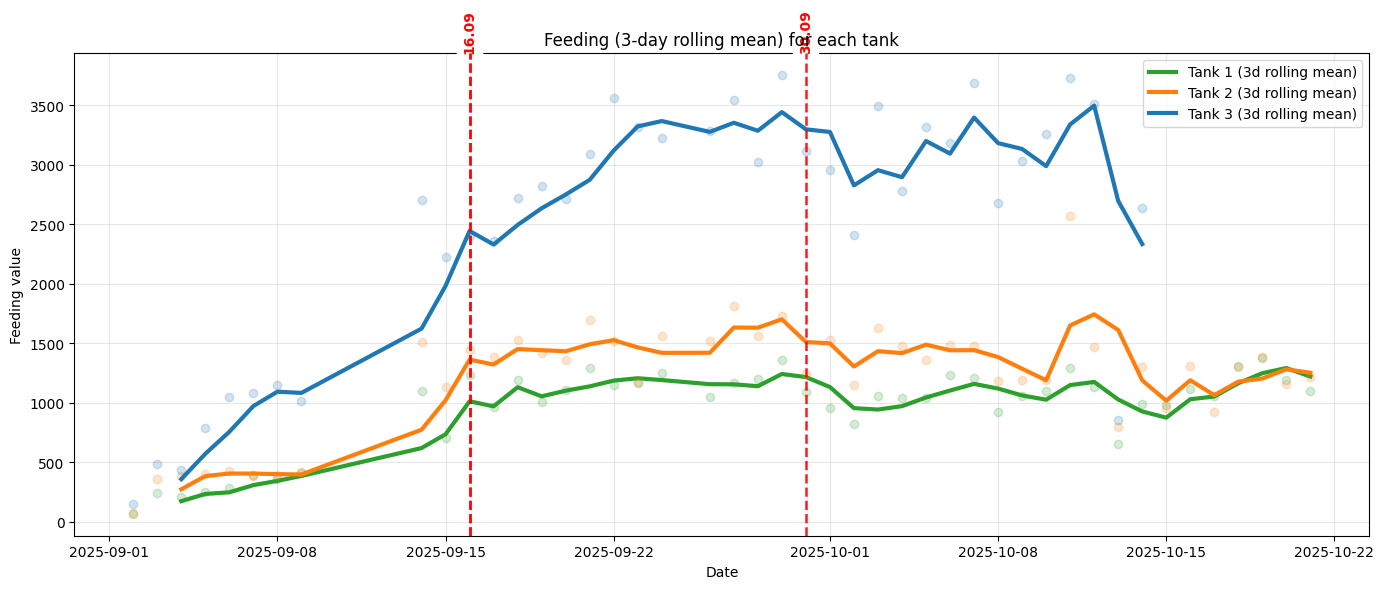

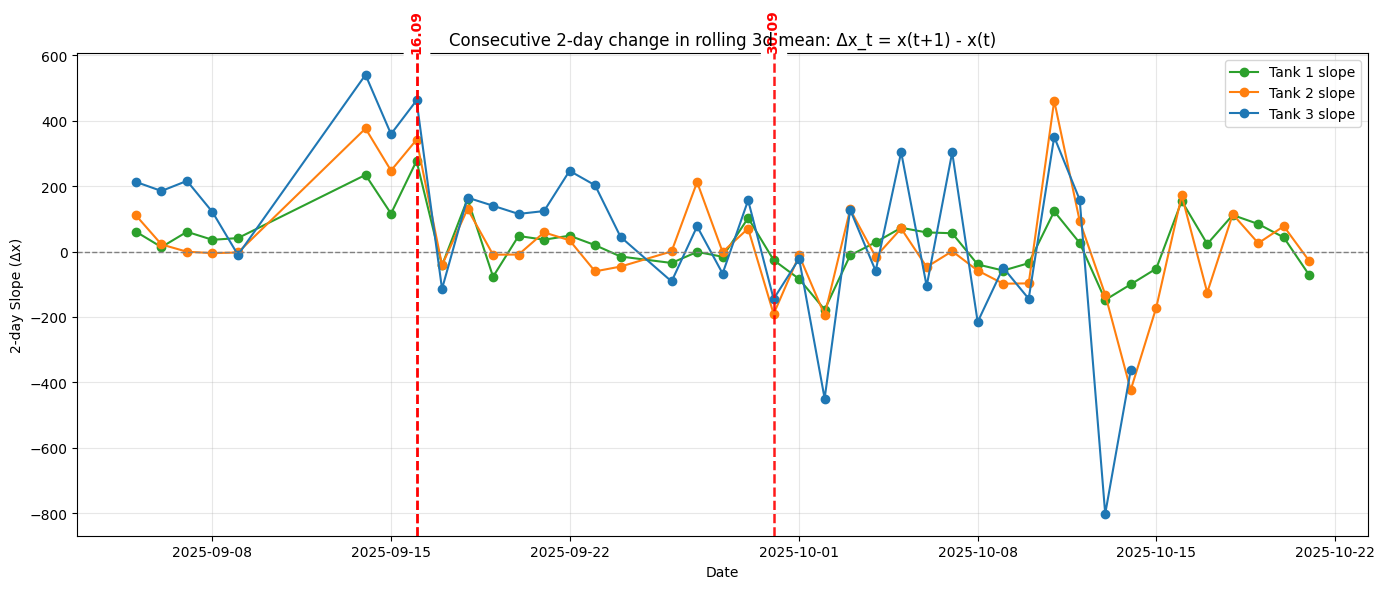

Slope Agreement and Correlation Table:
          Tank Pair  Slope Pearson r  Slope Spearman r  Direction Agreement %
0  Tank 1 vs Tank 2           0.7675            0.7738                73.8095
1  Tank 1 vs Tank 3           0.8240            0.8078                80.0000
2  Tank 2 vs Tank 3           0.7515            0.8076                80.0000

Slope Agreement and Correlation Table (z-normalized, slopes of z-scores):
          Tank Pair  Slope Pearson r  Slope Spearman r  Direction Agreement %
0  Tank 1 vs Tank 2           0.7675            0.7738                73.8095
1  Tank 1 vs Tank 3           0.8240            0.8078                80.0000
2  Tank 2 vs Tank 3           0.7515            0.8076                80.0000


In [155]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

# Ch2 is tank 1, Ch4 is tank 2, Ch6 is tank 3
channel_labels = {
    "Ch2": "Tank 1",
    "Ch4": "Tank 2",
    "Ch6": "Tank 3"
}

# Load the feeding values CSV
df = pd.read_csv('feeding_values.csv', parse_dates=['max_time'])
df.set_index('max_time', inplace=True)

# Only keep Ch2, Ch4, Ch6
channel_cols = ["Ch2", "Ch4", "Ch6"]
df = df[channel_cols]

# Resample to daily means only for dates with any value (skip days with all NaN)
df_daily = df.resample('D').mean()
df_daily = df_daily.dropna(how='all')  # Remove days with all NaN

# For tank 3 (Ch6), show feeding values only up to and including 12.10 (October 12th) for every year
if pd.api.types.is_datetime64_any_dtype(df_daily.index):
    mask_ch6 = (df_daily.index.month < 10) | ((df_daily.index.month == 10) & (df_daily.index.day <= 14))
    df_daily_plot = df_daily.copy()  # rolling means will use this
    df_daily_plot.loc[~mask_ch6, "Ch6"] = np.nan
else:
    df_daily_plot = df_daily

rolling_window = 3  # Use 3-day rolling mean as instructed

# List pairs of tanks to compare
col_pairs = []
for i, col1 in enumerate(channel_cols):
    for j, col2 in enumerate(channel_cols):
        if i < j:
            col_pairs.append((col1, col2))

# Define vertical line dates (as in original)
unique_years = sorted(set(df_daily_plot.index.year))
vertline_dates = []
for y in unique_years:
    try:
        vertline_dates.append(pd.Timestamp(year=y, month=9, day=16))
        vertline_dates.append(pd.Timestamp(year=y, month=9, day=30))
        vertline_dates.append(pd.Timestamp(year=y, month=9, day=16))
    except Exception:
        pass

# ==========
# 1. Plot rolling 3-day means (for reference)
# ==========
fig, ax = plt.subplots(figsize=(14, 6))
colors = ['tab:green', 'tab:orange', 'tab:blue']
rolling_means = {}
for i, col in enumerate(channel_cols):
    roll_mean = df_daily_plot[col].rolling(window=rolling_window, min_periods=3).mean()
    rolling_means[col] = roll_mean
    ax.plot(df_daily_plot.index, roll_mean, linewidth=3, label=f"{channel_labels[col]} (3d rolling mean)", color=colors[i])
    # Overlay raw data, optional
    ax.plot(df_daily_plot.index, df_daily_plot[col], marker='o', linestyle='', color=colors[i], alpha=0.2)

y_min, y_max = ax.get_ylim()
for vdate in vertline_dates:
    if vdate >= df_daily_plot.index.min() and vdate <= df_daily_plot.index.max():
        ax.axvline(vdate, color='red', linestyle='--', linewidth=1.8, alpha=0.9, zorder=10)
        label_str = vdate.strftime('%d.%m')
        ax.text(
            vdate, y_max, label_str,
            color='red', rotation=90, va='bottom', ha='center',
            fontsize=10, fontweight='bold', backgroundcolor="white"
        )
ax.set_ylim(y_min, y_max)
ax.set_ylabel("Feeding value")
ax.set_xlabel("Date")
ax.set_title("Feeding (3-day rolling mean) for each tank")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# ==========
# 2. Calculate per-tank 2-day slopes on rolling means
# ==========

slopes = {}
slope_dates = None  # The index after differencing will be 1 shorter than original
for col in channel_cols:
    roll_mean = rolling_means[col]
    # Slopes: Δx_t = x_{t+1} - x_t
    slope = roll_mean.diff().values[1:]  # .diff() gives NaN at [0], so skip it
    slopes[col] = slope
    # After .diff(), index aligns with second row onward ([1:])
    if slope_dates is None:
        slope_dates = roll_mean.index[1:]
    # Now, slopes[col] matches slope_dates

# ==========
# 3. Plot the slope time series for all tanks
# ==========
fig, ax = plt.subplots(figsize=(14, 6))
for i, col in enumerate(channel_cols):
    ax.plot(slope_dates, slopes[col], '-o', label=f"{channel_labels[col]} slope", color=colors[i])
ax.axhline(0, color='gray', linewidth=1, linestyle='--')
y_min, y_max = ax.get_ylim()
for vdate in vertline_dates:
    if vdate >= slope_dates.min() and vdate <= slope_dates.max():
        ax.axvline(vdate, color='red', linestyle='--', linewidth=1.8, alpha=0.9, zorder=10)
        label_str = vdate.strftime('%d.%m')
        ax.text(
            vdate, y_max, label_str,
            color='red', rotation=90, va='bottom', ha='center',
            fontsize=10, fontweight='bold', backgroundcolor="white"
        )
ax.set_ylim(y_min, y_max)
ax.set_ylabel("2-day Slope (Δx)")
ax.set_xlabel("Date")
ax.set_title("Consecutive 2-day change in rolling 3d mean: Δx_t = x(t+1) - x(t)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# ========== 
# 4. Quantify similarity/direction agreement for each tank pair
# ==========

summary_results = []

for (col1, col2) in col_pairs:
    # Keep only elements where both tanks have non-NaN slopes for the pair
    valid_mask = ~np.isnan(slopes[col1]) & ~np.isnan(slopes[col2])
    s1, s2 = slopes[col1][valid_mask], slopes[col2][valid_mask]  # these are np.arrays

    # ---- (a) Direction agreement percentage ----
    # This is the proportion where both slopes are positive or both negative or both zero (signs match)
    sign1, sign2 = np.sign(s1), np.sign(s2)
    matching_direction = (sign1 == sign2) & (~np.isnan(sign1)) & (~np.isnan(sign2))
    percent_direction_agreement = 100 * np.sum(matching_direction) / len(s1) if len(s1) > 0 else np.nan

    # ---- (b) Pearson correlation on slopes ----
    slope_pearson_corr = pearsonr(s1, s2)[0] if len(s1) > 1 else np.nan

    # ---- (c) Spearman correlation on slopes ----
    slope_spearman_corr = spearmanr(s1, s2).correlation if len(s1) > 1 else np.nan

    # Store for summary table
    summary_results.append({
        "Tank Pair": f"{channel_labels[col1]} vs {channel_labels[col2]}",
        "Slope Pearson r": slope_pearson_corr,
        "Slope Spearman r": slope_spearman_corr,
        "Direction Agreement %": percent_direction_agreement
    })

# ========== 
# 5. (Optional) Repeat after z-scoring each tank's rolling mean before slope
# ==========

slopes_z = {}
for col in channel_cols:
    roll = rolling_means[col]
    # Normalize (z-score) ignoring NaNs
    roll_mean = roll.mean(skipna=True)
    roll_std = roll.std(skipna=True)
    roll_z = (roll - roll_mean) / roll_std
    slope_z = roll_z.diff().values[1:]
    slopes_z[col] = slope_z

summary_results_z = []
for (col1, col2) in col_pairs:
    valid_mask = ~np.isnan(slopes_z[col1]) & ~np.isnan(slopes_z[col2])
    s1, s2 = slopes_z[col1][valid_mask], slopes_z[col2][valid_mask]
    sign1, sign2 = np.sign(s1), np.sign(s2)
    matching_direction = (sign1 == sign2) & (~np.isnan(sign1)) & (~np.isnan(sign2))
    percent_direction_agreement = 100 * np.sum(matching_direction) / len(s1) if len(s1) > 0 else np.nan
    slope_pearson_corr = pearsonr(s1, s2)[0] if len(s1) > 1 else np.nan
    slope_spearman_corr = spearmanr(s1, s2).correlation if len(s1) > 1 else np.nan
    summary_results_z.append({
        "Tank Pair": f"{channel_labels[col1]} vs {channel_labels[col2]}",
        "Slope Pearson r": slope_pearson_corr,
        "Slope Spearman r": slope_spearman_corr,
        "Direction Agreement %": percent_direction_agreement
    })

# ==========
# 6. Display summary table
# ==========
summary_df = pd.DataFrame(summary_results)
summary_df_z = pd.DataFrame(summary_results_z)

print("Slope Agreement and Correlation Table:")
print(summary_df.round(4))

print("\nSlope Agreement and Correlation Table (z-normalized, slopes of z-scores):")
print(summary_df_z.round(4))

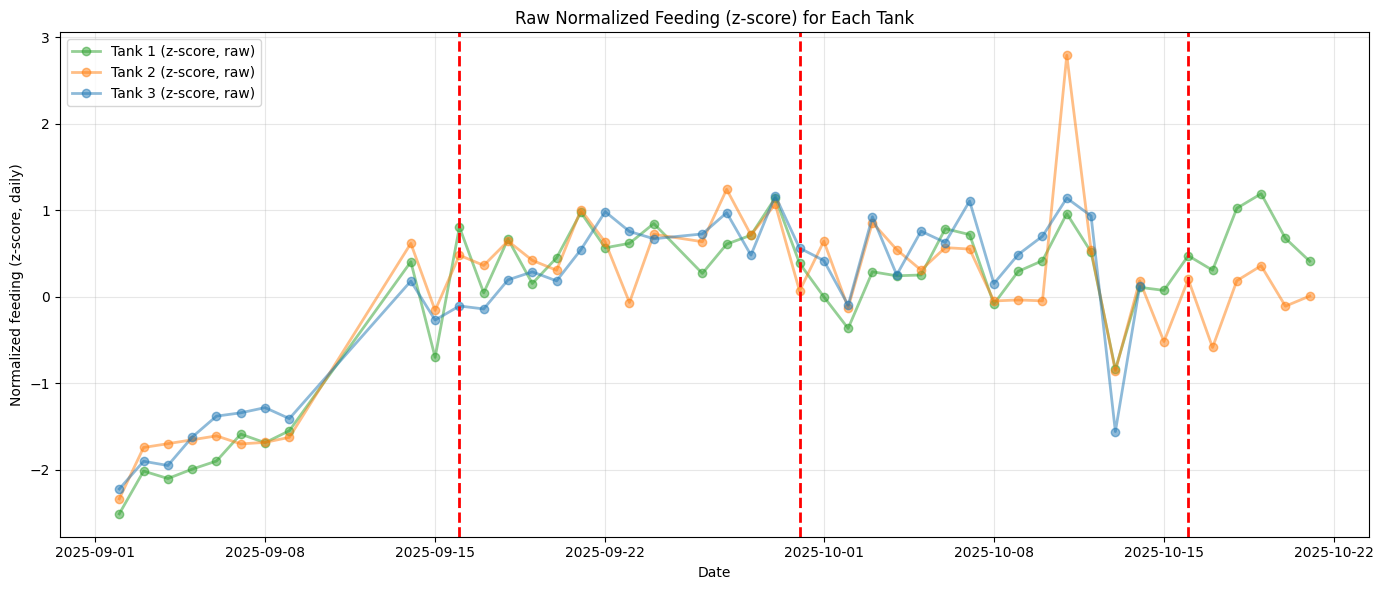

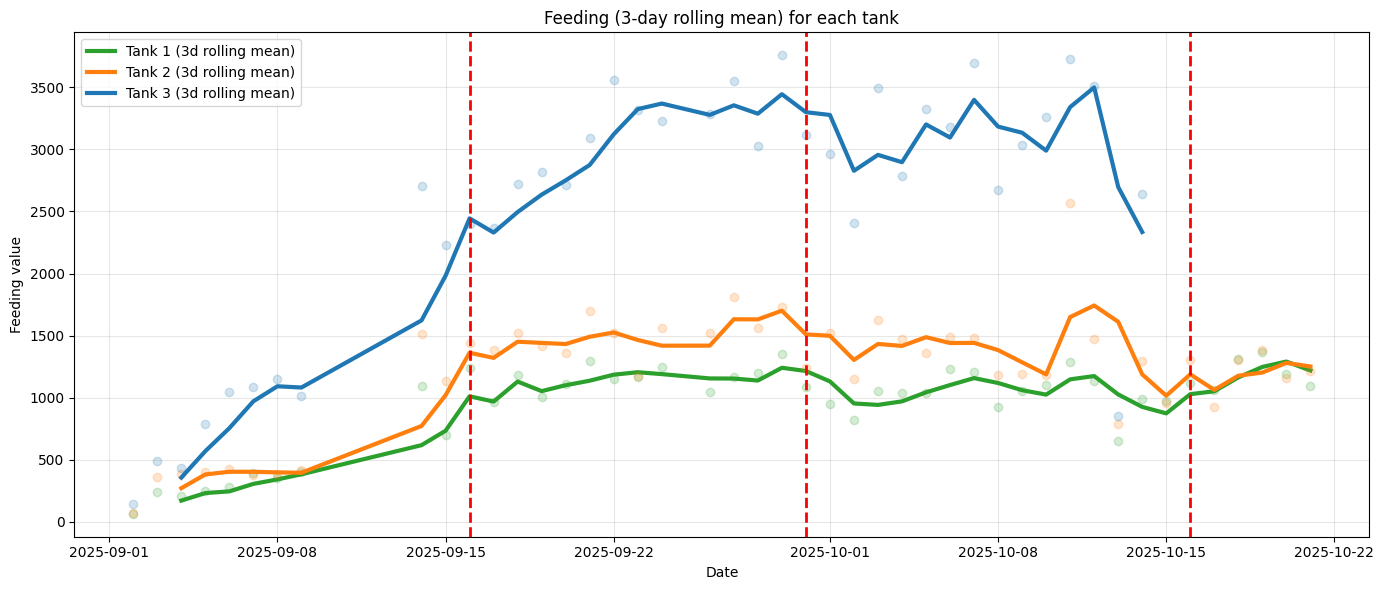

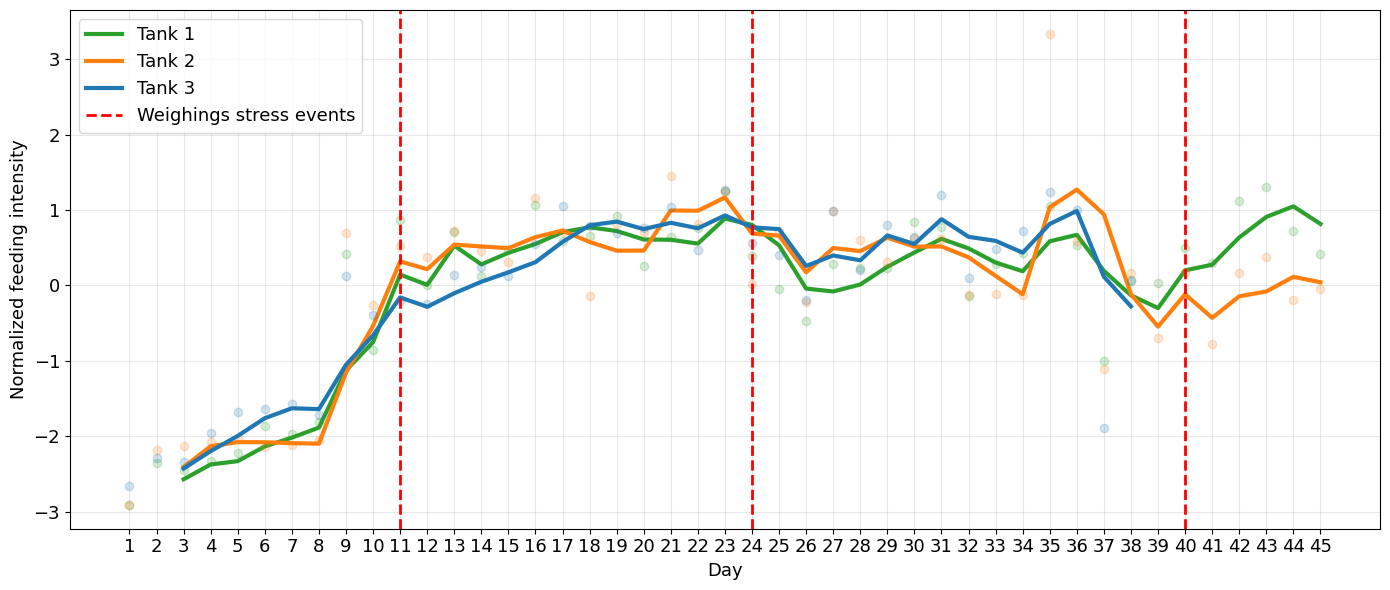

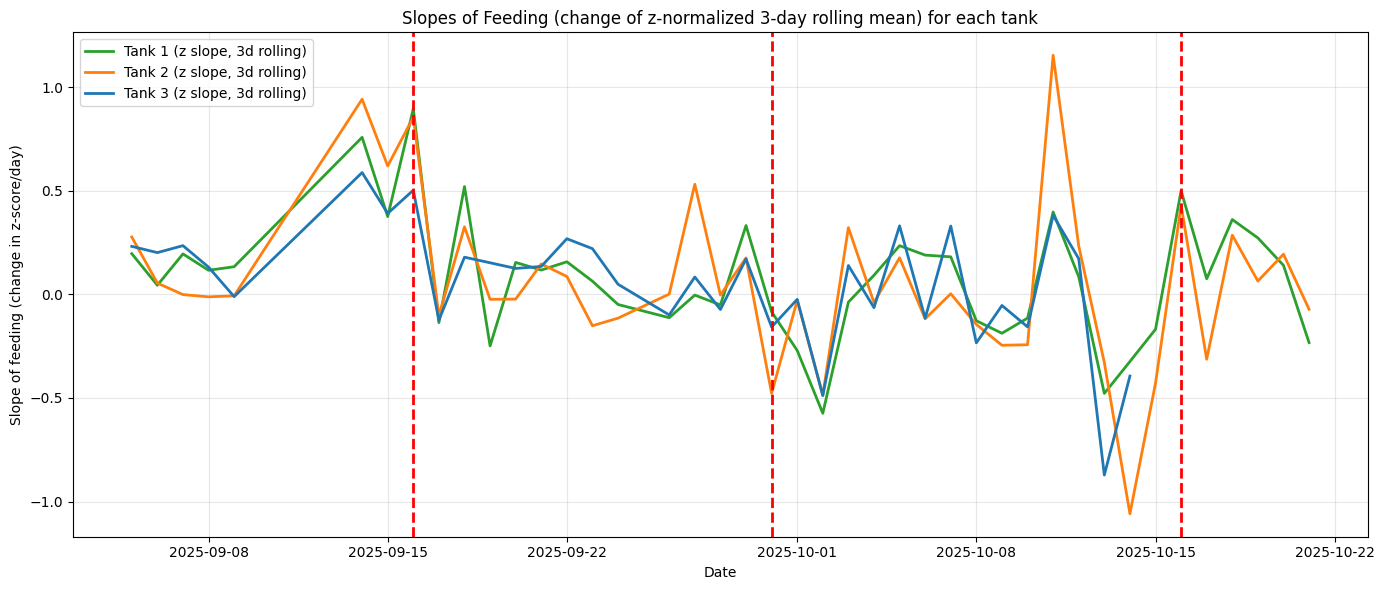

In [166]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# Ch2 is tank 1, Ch4 is tank 2, Ch6 is tank 3
channel_labels = {
    "Ch2": "Tank 1",
    "Ch4": "Tank 2",
    "Ch6": "Tank 3"
}

# Load the feeding values CSV
df = pd.read_csv('feeding_values.csv', parse_dates=['max_time'])
df.set_index('max_time', inplace=True)

# Only keep Ch2, Ch4, Ch6
channel_cols = ["Ch2", "Ch4", "Ch6"]
df = df[channel_cols]

# Resample to daily means only for dates with any value (skip days with all NaN)
df_daily = df.resample('D').mean()
df_daily = df_daily.dropna(how='all')  # Remove days with all NaN

# For tank 3 (Ch6), show feeding values only up to and including 12.10 (October 12th) for every year
if pd.api.types.is_datetime64_any_dtype(df_daily.index):
    mask_ch6 = (df_daily.index.month < 10) | ((df_daily.index.month == 10) & (df_daily.index.day <= 14))
    df_daily_plot = df_daily.copy()
    df_daily_plot.loc[~mask_ch6, "Ch6"] = np.nan
else:
    df_daily_plot = df_daily

rolling_window = 3  # still use 3-day rolling mean

colors = ['tab:green', 'tab:orange', 'tab:blue']

# ==========
# 0. Plot normalized feeding (z-score) for each tank on raw (not rolling) daily values
# ==========
fig, ax = plt.subplots(figsize=(14, 6))
for i, col in enumerate(channel_cols):
    v = df_daily_plot[col]
    norm_mean = v.mean(skipna=True)
    norm_std = v.std(skipna=True)
    v_z = (v - norm_mean) / norm_std
    ax.plot(df_daily_plot.index, v_z, linewidth=2, marker='o', label=f"{channel_labels[col]} (z-score, raw)", color=colors[i], alpha=0.5)
# Add the same stress events verticals as other plots
for year in sorted(set(df_daily_plot.index.year)):
    for day_month in [("09-16"), ("09-30"), ("10-16")]:
        try:
            dt = pd.Timestamp(f"{year}-{day_month}")
            ax.axvline(dt, color='red', lw=2, ls="--")
        except:
            pass
ax.set_ylabel("Normalized feeding (z-score, daily)")
ax.set_xlabel("Date")
ax.set_title("Raw Normalized Feeding (z-score) for Each Tank")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# ==========
# 1. Plot rolling 3-day means (for reference, unchanged)
# ==========
fig, ax = plt.subplots(figsize=(14, 6))
rolling_means = {}
for i, col in enumerate(channel_cols):
    roll_mean = df_daily_plot[col].rolling(window=rolling_window, min_periods=3).mean()
    rolling_means[col] = roll_mean
    ax.plot(df_daily_plot.index, roll_mean, linewidth=3, label=f"{channel_labels[col]} (3d rolling mean)", color=colors[i])
    ax.plot(df_daily_plot.index, df_daily_plot[col], marker='o', linestyle='', color=colors[i], alpha=0.2)

# Add vertical red lines at 16.09, 30.09, and 16.10 for each year present in the data
for year in sorted(set(df_daily_plot.index.year)):
    for day_month in [("09-16"), ("09-30"), ("10-16")]:
        try:
            dt = pd.Timestamp(f"{year}-{day_month}")
            ax.axvline(dt, color='red', lw=2, ls="--")
        except:
            pass

ax.set_ylabel("Feeding value")
ax.set_xlabel("Date")
ax.set_title("Feeding (3-day rolling mean) for each tank")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# ==========
# 2. Plot same info but normalized (z-score) for each tank, with customizations
# ==========

fig, ax = plt.subplots(figsize=(14, 6))
x_pos = np.arange(len(df_daily_plot.index)) + 1  # x axis positions: 1, 2, 3, ...

rolling_means_z = {}
for i, col in enumerate(channel_cols):
    roll_mean = rolling_means[col]
    # z-score just on available data (ignore NaNs)
    z_mean = roll_mean.mean(skipna=True)
    z_std = roll_mean.std(skipna=True)
    roll_mean_z = (roll_mean - z_mean) / z_std
    rolling_means_z[col] = roll_mean_z
    ax.plot(x_pos, roll_mean_z, linewidth=3, label=f"Tank {i+1}", color=colors[i])
    # Also plot points (z)
    raw_z = (df_daily_plot[col] - z_mean) / z_std
    ax.plot(x_pos, raw_z, marker='o', linestyle='', color=colors[i], alpha=0.2)

# Find all red vertical lines event positions and only keep unique ones for labeling
event_positions = []
event_labels = []
for year in sorted(set(df_daily_plot.index.year)):
    for day_month in [("09-16"), ("09-30"), ("10-16")]:
        try:
            dt = pd.Timestamp(f"{year}-{day_month}")
            if dt in df_daily_plot.index:
                ix = list(df_daily_plot.index).index(dt)
            else:
                # Find nearest date in index
                ix = np.abs((df_daily_plot.index - dt).days).argmin()
            event_positions.append(x_pos[ix])
        except:
            pass

# Remove duplicates
event_positions = sorted(set(event_positions))
# Draw vertical line and label once
for ep in event_positions:
    ax.axvline(ep, color="red", lw=2, ls="--", label="Weighings stress events" if ep == event_positions[0] else None)

ax.set_ylabel("Normalized feeding intensity", fontsize=13)
ax.set_xlabel("Day", fontsize=13)
ax.set_xticks(x_pos)
ax.set_xticklabels([str(i) for i in x_pos], fontsize=13)
ax.tick_params(axis='y', labelsize=13)
# Remove the plot title
# ax.set_title("")
ax.grid(True, alpha=0.3)
# Place legend outside or best location, only 1 label for vertical line
handles, labels = ax.get_legend_handles_labels()
from collections import OrderedDict
unique = OrderedDict()
for h, l in zip(handles, labels):
    if l is not None and l != '':
        unique[l] = h
ax.legend(unique.values(), unique.keys(), fontsize=13)
plt.tight_layout()
plt.show()

# ==========
# 3. Plot the normalized (z-score) slopes of the rolling means for each tank
# ==========
fig, ax = plt.subplots(figsize=(14, 6))
for i, col in enumerate(channel_cols):
    roll_mean_z = rolling_means_z[col]
    slope_z = roll_mean_z.diff()
    ax.plot(df_daily_plot.index, slope_z, linewidth=2, label=f"{channel_labels[col]} (z slope, 3d rolling)", color=colors[i])

# Add vertical red lines at 16.09, 30.09, and 16.10 for each year present in the data
for year in sorted(set(df_daily_plot.index.year)):
    for day_month in [("09-16"), ("09-30"), ("10-16")]:
        try:
            dt = pd.Timestamp(f"{year}-{day_month}")
            ax.axvline(dt, color='red', lw=2, ls="--")
        except:
            pass

ax.set_ylabel("Slope of feeding (change in z-score/day)")
ax.set_xlabel("Date")
ax.set_title("Slopes of Feeding (change of z-normalized 3-day rolling mean) for each tank")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [254]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr
from datetime import datetime

# Ch2 is tank 1, Ch4 is tank 2, Ch6 is tank 3
channel_labels = {
    "Ch2": "Tank 1",
    "Ch4": "Tank 2",
    "Ch6": "Tank 3"
}

# Load the feeding values CSV
df = pd.read_csv('feeding_values.csv', parse_dates=['max_time'])
df.set_index('max_time', inplace=True)

# Only keep Ch2, Ch4, Ch6
channel_cols = ["Ch2", "Ch4", "Ch6"]
df = df[channel_cols]

# Resample to daily means only for dates with any value (skip days with all NaN)
df_daily = df.resample('D').mean()
df_daily = df_daily.dropna(how='all')  # Remove days with all NaN

# Normalize feeding for each tank (z-score per tank, using mean and std of each column)
df_normalized = df_daily.copy()
for col in channel_cols:
    col_mean = df_normalized[col].mean(skipna=True)
    col_std = df_normalized[col].std(skipna=True)
    if col_std != 0:
        df_normalized[col] = (df_normalized[col] - col_mean) / col_std

# For tank 3 (Ch6), show feeding values only up to and including 14.10 (October 14th) for every year
if pd.api.types.is_datetime64_any_dtype(df_normalized.index):
    mask_ch6 = (df_normalized.index.month < 10) | ((df_normalized.index.month == 10) & (df_normalized.index.day <= 14))
    df_normalized_plot = df_normalized.copy()
    df_normalized_plot.loc[~mask_ch6, "Ch6"] = np.nan
else:
    df_normalized_plot = df_normalized

rolling_window = 3  # 3-day rolling mean

# --- Calculate rolling means for all tanks using normalized data ---
rolling_means_z = {}
for col in channel_cols:
    rolling_means_z[col] = df_normalized_plot[col].rolling(window=rolling_window, min_periods=3).mean()

rolling_means_z_df = pd.DataFrame(rolling_means_z, index=df_normalized_plot.index)

print("=== Pearson correlation on normalized rolling 3-day means (all dates) ===")
for i, col1 in enumerate(channel_cols):
    for j, col2 in enumerate(channel_cols):
        if j > i:
            x = rolling_means_z_df[col1].dropna()
            y = rolling_means_z_df[col2].dropna()
            # Align on dates where both are non-NaN
            aligned = pd.concat([x, y], axis=1).dropna()
            if len(aligned) > 2:
                r, p = pearsonr(aligned[col1], aligned[col2])
                print(f"{channel_labels[col1]} vs {channel_labels[col2]}: r = {r:.3f}, p = {p:.3g}")
            else:
                print(f"{channel_labels[col1]} vs {channel_labels[col2]}: Not enough data.")

# --- Take into account ONLY the first 2 stress events in the dataset ---
# Stress events: 16.09, 30.09, 16.10 every year in data
all_event_dates = []
for year in sorted(set(df_normalized_plot.index.year)):
    for day_month in [("09-16"), ("09-30"), ("10-16")]:
        try:
            dt = pd.Timestamp(f"{year}-{day_month}")
            # Use nearest date in index if not present
            if dt not in df_normalized_plot.index:
                dt = df_normalized_plot.index[np.abs((df_normalized_plot.index - dt).days).argmin()]
            all_event_dates.append(dt)
        except Exception:
            pass

all_event_dates = sorted(set(all_event_dates))
first_two_events = all_event_dates[:2]

post_event_indices = []
for event in first_two_events:
    try:
        idx = df_normalized_plot.index.get_loc(event)
        # Get the next 3 points after the event date (including the event itself)
        for offset in range(3):
            if idx + offset < len(df_normalized_plot):
                post_event_indices.append(df_normalized_plot.index[idx + offset])
    except Exception:
        continue

post_event_indices = sorted(set(post_event_indices))
rolling_means_z_postevent = rolling_means_z_df.loc[post_event_indices]

print("\n=== Pearson correlation (normalized rolling) - only 3 days after the FIRST 2 stress events ===")
for i, col1 in enumerate(channel_cols):
    for j, col2 in enumerate(channel_cols):
        if j > i:
            x = rolling_means_z_postevent[col1].dropna()
            y = rolling_means_z_postevent[col2].dropna()
            aligned = pd.concat([x, y], axis=1).dropna()
            if len(aligned) > 2:
                r, p = pearsonr(aligned[col1], aligned[col2])
                print(f"{channel_labels[col1]} vs {channel_labels[col2]}: r = {r:.3f}, p = {p:.3g}")
            else:
                print(f"{channel_labels[col1]} vs {channel_labels[col2]}: Not enough data.")

# --- Pearson correlation on normalized rolling means (all dates EXCEPT 3 points after first 2 stress events) ---
non_post_event_indices = df_normalized_plot.index.difference(post_event_indices)
rolling_means_z_not_stress = rolling_means_z_df.loc[non_post_event_indices]

print("\n=== Pearson correlation (normalized rolling) - WITHOUT the 3 days after the FIRST 2 stress events ===")
for i, col1 in enumerate(channel_cols):
    for j, col2 in enumerate(channel_cols):
        if j > i:
            x = rolling_means_z_not_stress[col1].dropna()
            y = rolling_means_z_not_stress[col2].dropna()
            aligned = pd.concat([x, y], axis=1).dropna()
            if len(aligned) > 2:
                r, p = pearsonr(aligned[col1], aligned[col2])
                print(f"{channel_labels[col1]} vs {channel_labels[col2]}: r = {r:.3f}, p = {p:.3g}")
            else:
                print(f"{channel_labels[col1]} vs {channel_labels[col2]}: Not enough data.")

# --- Do the same but on the normalized real (not rolling) daily data ---
print("\n=== Pearson correlation on normalized raw daily feeding data (all dates) ===")
for i, col1 in enumerate(channel_cols):
    for j, col2 in enumerate(channel_cols):
        if j > i:
            x = df_normalized_plot[col1].dropna()
            y = df_normalized_plot[col2].dropna()
            aligned = pd.concat([x, y], axis=1).dropna()
            if len(aligned) > 2:
                r, p = pearsonr(aligned[col1], aligned[col2])
                print(f"{channel_labels[col1]} vs {channel_labels[col2]}: r = {r:.3f}, p = {p:.3g}")
            else:
                print(f"{channel_labels[col1]} vs {channel_labels[col2]}: Not enough data.")

raw_postevent_normalized = df_normalized_plot.loc[post_event_indices]
print("\n=== Pearson correlation (normalized raw data) - only 3 days after the FIRST 2 stress events ===")
for i, col1 in enumerate(channel_cols):
    for j, col2 in enumerate(channel_cols):
        if j > i:
            x = raw_postevent_normalized[col1].dropna()
            y = raw_postevent_normalized[col2].dropna()
            aligned = pd.concat([x, y], axis=1).dropna()
            if len(aligned) > 2:
                r, p = pearsonr(aligned[col1], aligned[col2])
                print(f"{channel_labels[col1]} vs {channel_labels[col2]}: r = {r:.3f}, p = {p:.3g}")
            else:
                print(f"{channel_labels[col1]} vs {channel_labels[col2]}: Not enough data.")

# --- Pearson correlation on normalized raw data (all dates EXCEPT 3 points after first 2 stress events) ---
raw_not_stress_normalized = df_normalized_plot.loc[non_post_event_indices]
print("\n=== Pearson correlation (normalized raw data) - WITHOUT the 3 days after the FIRST 2 stress events ===")
for i, col1 in enumerate(channel_cols):
    for j, col2 in enumerate(channel_cols):
        if j > i:
            x = raw_not_stress_normalized[col1].dropna()
            y = raw_not_stress_normalized[col2].dropna()
            aligned = pd.concat([x, y], axis=1).dropna()
            if len(aligned) > 2:
                r, p = pearsonr(aligned[col1], aligned[col2])
                print(f"{channel_labels[col1]} vs {channel_labels[col2]}: r = {r:.3f}, p = {p:.3g}")
            else:
                print(f"{channel_labels[col1]} vs {channel_labels[col2]}: Not enough data.")

     

=== Pearson correlation on normalized rolling 3-day means (all dates) ===
Tank 1 vs Tank 2: r = 0.920, p = 2.54e-18
Tank 1 vs Tank 3: r = 0.972, p = 5.98e-23
Tank 2 vs Tank 3: r = 0.952, p = 4.15e-19

=== Pearson correlation (normalized rolling) - only 3 days after the FIRST 2 stress events ===
Tank 1 vs Tank 2: r = 0.975, p = 0.000921
Tank 1 vs Tank 3: r = 0.658, p = 0.156
Tank 2 vs Tank 3: r = 0.700, p = 0.122

=== Pearson correlation (normalized rolling) - WITHOUT the 3 days after the FIRST 2 stress events ===
Tank 1 vs Tank 2: r = 0.920, p = 9.2e-16
Tank 1 vs Tank 3: r = 0.984, p = 1.23e-22
Tank 2 vs Tank 3: r = 0.963, p = 2.03e-17

=== Pearson correlation on normalized raw daily feeding data (all dates) ===
Tank 1 vs Tank 2: r = 0.883, p = 1.06e-15
Tank 1 vs Tank 3: r = 0.942, p = 1.3e-18
Tank 2 vs Tank 3: r = 0.905, p = 6.53e-15

=== Pearson correlation (normalized raw data) - only 3 days after the FIRST 2 stress events ===
Tank 1 vs Tank 2: r = 0.534, p = 0.275
Tank 1 vs Tank 3:

In [255]:
df = pd.read_csv('feeding_values.csv', parse_dates=['max_time'])
df.head()

,max_time,Ch1,Ch2,Ch3,Ch4,Ch5,Ch6
0,2025-09-02 15:17:06,41,46,43,42,77,106
1,2025-09-02 18:11:54,98,85,11,102,163,188
2,2025-09-03 06:54:42,230,349,177,433,262,215
3,2025-09-03 09:44:48,205,219,145,570,780,581
4,2025-09-03 11:24:42,177,240,185,321,593,370


RandomForest Grid SearchCV and Cross-Validation Results:

Target: Ch1
Best Parameters: {'max_depth': 4, 'min_samples_split': 5, 'n_estimators': 100}
Mean CV RMSE: 324.48 (+/- 149.74)

Target: Ch2
Best Parameters: {'max_depth': 4, 'min_samples_split': 2, 'n_estimators': 50}
Mean CV RMSE: 370.85 (+/- 156.01)

Target: Ch3
Best Parameters: {'max_depth': 2, 'min_samples_split': 5, 'n_estimators': 50}
Mean CV RMSE: 240.70 (+/- 126.91)

Target: Ch4
Best Parameters: {'max_depth': 4, 'min_samples_split': 10, 'n_estimators': 200}
Mean CV RMSE: 683.87 (+/- 550.02)

Target: Ch5
Best Parameters: {'max_depth': 2, 'min_samples_split': 10, 'n_estimators': 200}
Mean CV RMSE: 1121.96 (+/- 616.73)

Target: Ch6
Best Parameters: {'max_depth': 2, 'min_samples_split': 2, 'n_estimators': 100}
Mean CV RMSE: 1516.47 (+/- 522.77)


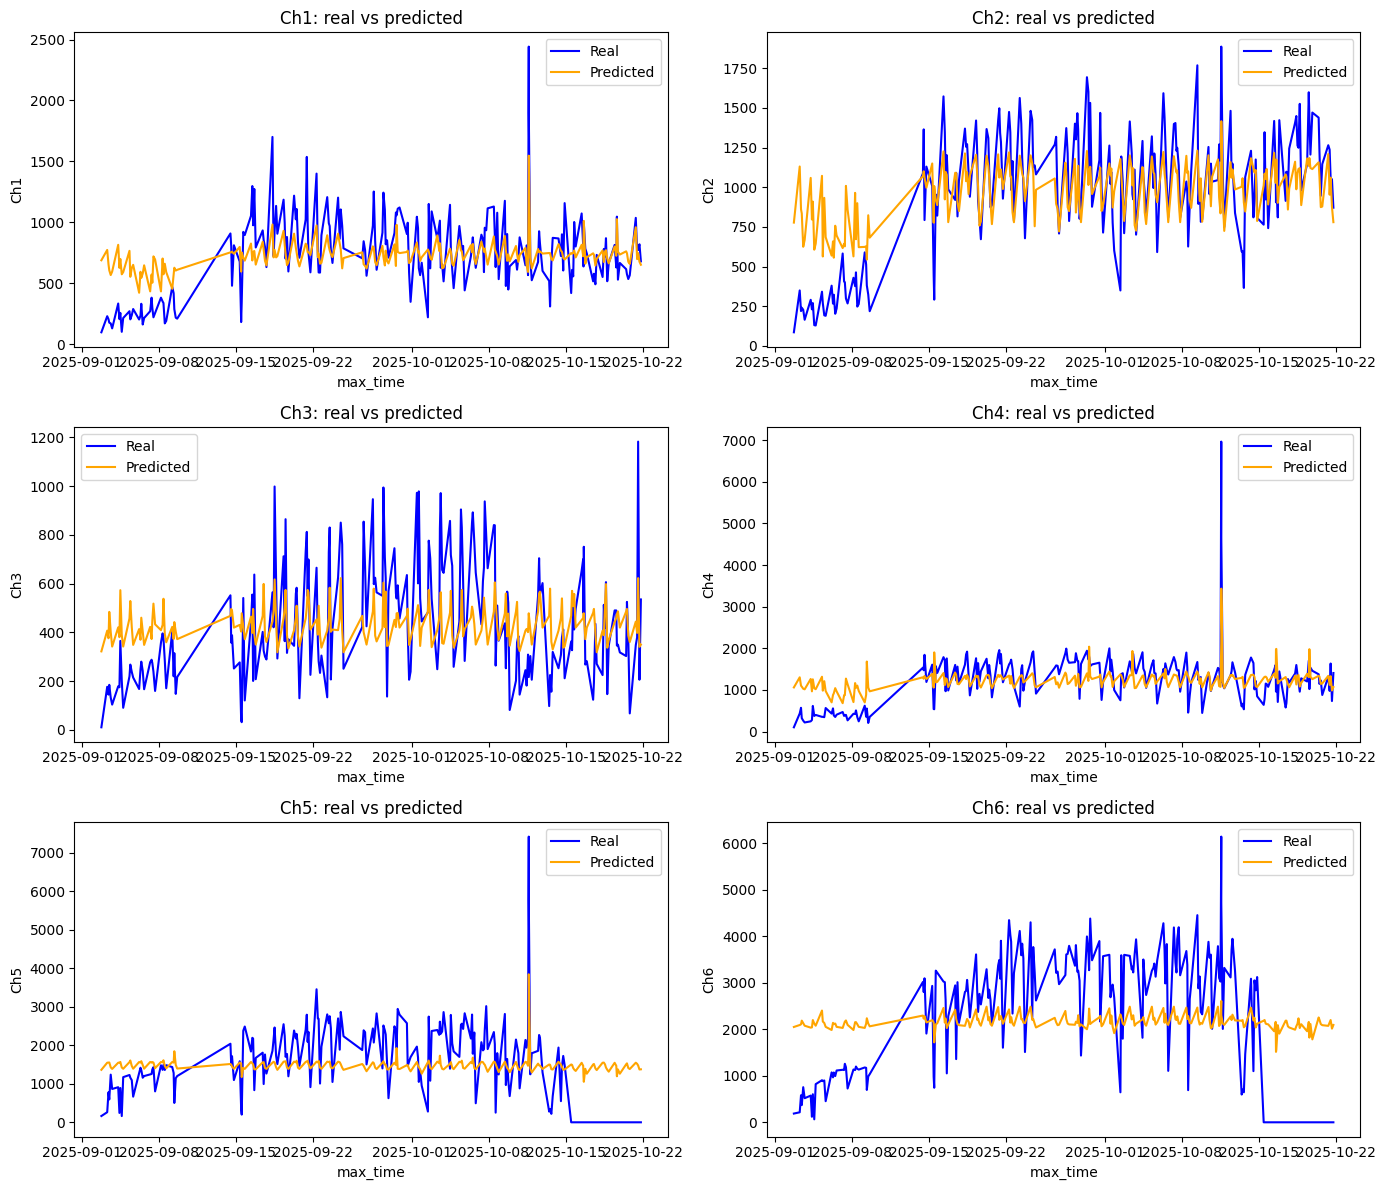

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, cross_val_score, KFold
from sklearn.metrics import make_scorer, mean_squared_error

# Read the CSV with max_time as parsed dates
df = pd.read_csv('feeding_values.csv', parse_dates=['max_time'])

# Add column for time_of_day as numeric (e.g., 15.28 for 15:17)
df['time_of_day'] = df['max_time'].dt.hour + df['max_time'].dt.minute / 60

# Add previous_time_since_feeding in minutes (NaN for the first row)
df['previous_time_since_feeding'] = df['max_time'].diff().dt.total_seconds() / 60

# Drop the first row because previous_time_since_feeding is NaN there
df_model = df.dropna(subset=['previous_time_since_feeding']).reset_index(drop=True)

# Features and targets
feature_cols = ['time_of_day', 'previous_time_since_feeding']
target_cols = ['Ch1', 'Ch2', 'Ch3', 'Ch4', 'Ch5', 'Ch6']

X = df_model[feature_cols].values
results = {}

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [2, 3, 4],
    'min_samples_split': [2, 5, 10]
}

cv = KFold(n_splits=3, shuffle=True, random_state=42)

print("RandomForest Grid SearchCV and Cross-Validation Results:")
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()

for idx, target in enumerate(target_cols):
    y = df_model[target].values

    rf = RandomForestRegressor(random_state=42)
    grid = GridSearchCV(
        rf,
        param_grid,
        scoring=make_scorer(mean_squared_error, greater_is_better=False),
        cv=cv,
        n_jobs=-1
    )
    grid.fit(X, y)

    best = grid.best_estimator_
    scores = cross_val_score(
        best,
        X,
        y,
        scoring=make_scorer(mean_squared_error, greater_is_better=False),
        cv=cv
    )
    print(f"\nTarget: {target}")
    print("Best Parameters:", grid.best_params_)
    print("Mean CV RMSE: {:.2f} (+/- {:.2f})".format(np.sqrt(-scores.mean()), np.sqrt(scores.std())))
    results[target] = {
        'best_params': grid.best_params_,
        'rmse': np.sqrt(-scores.mean())
    }

    # Plot: True vs Predicted for this target
    y_pred = best.predict(X)
    ax = axes[idx]
    ax.plot(df_model['max_time'], y, label='Real', color='blue')
    ax.plot(df_model['max_time'], y_pred, label='Predicted', color='orange')
    ax.set_title(f"{target}: real vs predicted")
    ax.set_xlabel('max_time')
    ax.set_ylabel(target)
    ax.legend()

plt.tight_layout()
plt.show()

In [7]:
pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 61.8 kB/s  0:00:28 eta 0:00:02m
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd

df = pd.read_parquet("/Volumes/My Book/exp_1/sw/feeding_times_exp1.parquet")
df




,index,time
0,2568,2021-01-01 08:00:00
1,4460,2021-01-01 11:09:12
2,14109,2021-01-02 08:00:00
3,24284,2021-01-03 08:00:00
4,26907,2021-01-03 12:22:18
5,29322,2021-01-03 16:23:48
6,39005,2021-01-04 08:00:00
7,41494,2021-01-04 12:08:54
8,51024,2021-01-05 08:00:00
9,53674,2021-01-05 12:25:00


In [ ]:
sw/feeding_features/features.parquet 
29-Oct-2024 09:14:50